In [3]:
import pandas as pd

# Load the dataset
dataset = pd.read_csv("speechsentiment.csv")

# Drop any rows with missing values
dataset.dropna(inplace=True)

# Initialize a list to hold the chunks
dfs = []

# Group the data by the 'Title' column
grouped = dataset.groupby('Title')

# Initialize a counter to keep track of the group number
group_number = 1

# Iterate over each group
for title, group in grouped:
    # Calculate the number of chunks of 32 rows for this group
    num_chunks = len(group) // 32
    
    # Split the group into chunks of 32 rows and add them to the list
    for i in range(num_chunks):
        chunk = group.iloc[i*32:(i+1)*32]
        dfs.append(chunk)
        # Print the group number and the chunk
        print(f"Group {group_number}, Chunk {i+1}")
        print(chunk)
        print()  # Adds an empty line for better readability

    # Increment the group number for the next title
    group_number += 1



Group 1, Chunk 1
            Unnamed: 0     Personality  \
984   03-12-1991 00:00  Nelson Mandela   
985   22-06-1990 00:00  Nelson Mandela   
986   22-06-1990 00:00  Nelson Mandela   
987   22-06-1990 00:00  Nelson Mandela   
988   22-06-1990 00:00  Nelson Mandela   
989   22-06-1990 00:00  Nelson Mandela   
990   22-06-1990 00:00  Nelson Mandela   
991   22-06-1990 00:00  Nelson Mandela   
992   22-06-1990 00:00  Nelson Mandela   
993   22-06-1990 00:00  Nelson Mandela   
994   22-06-1990 00:00  Nelson Mandela   
995   22-06-1990 00:00  Nelson Mandela   
996   22-06-1990 00:00  Nelson Mandela   
997   22-06-1990 00:00  Nelson Mandela   
998   22-06-1990 00:00  Nelson Mandela   
999   22-06-1990 00:00  Nelson Mandela   
1000  22-06-1990 00:00  Nelson Mandela   
1001  22-06-1990 00:00  Nelson Mandela   
1002  22-06-1990 00:00  Nelson Mandela   
1003  22-06-1990 00:00  Nelson Mandela   
1004  22-06-1990 00:00  Nelson Mandela   
1005  22-06-1990 00:00  Nelson Mandela   
1006  22-06-1990 

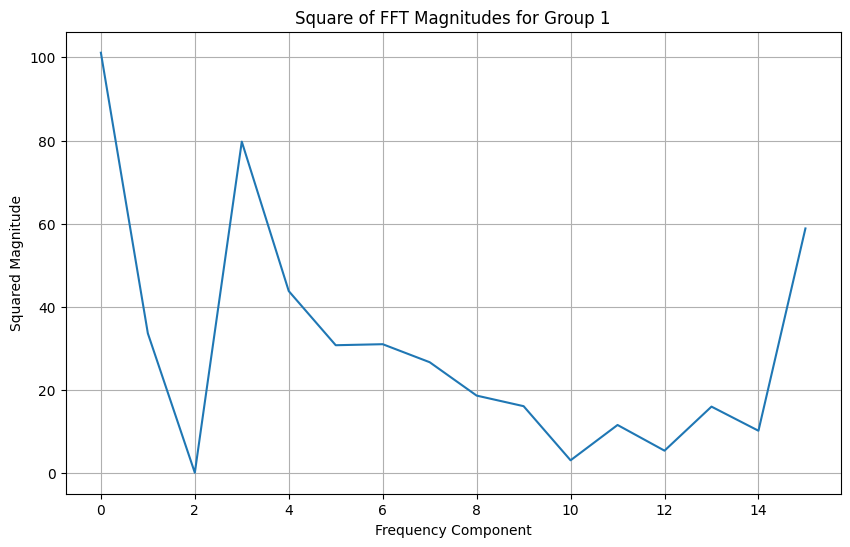

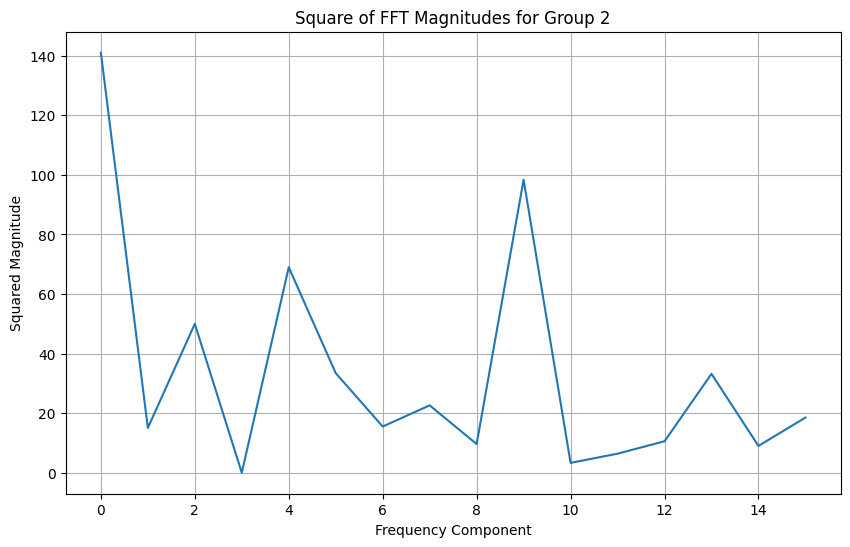

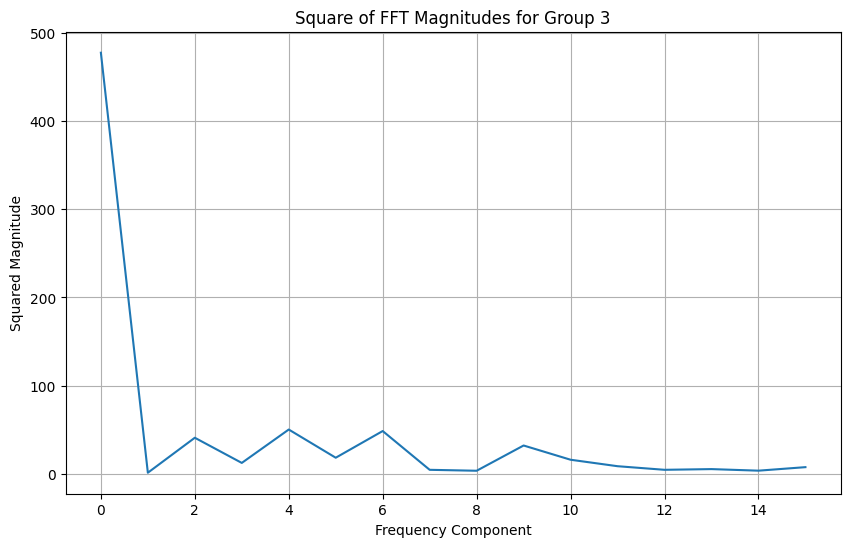

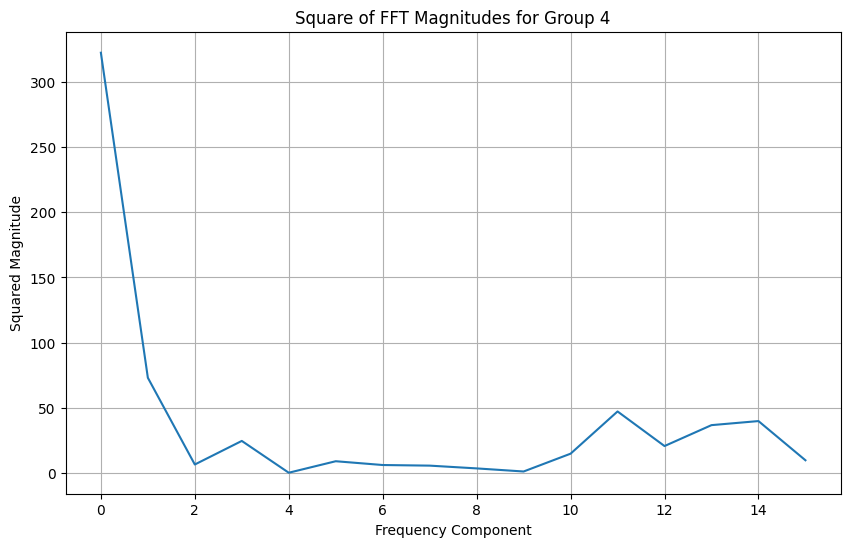

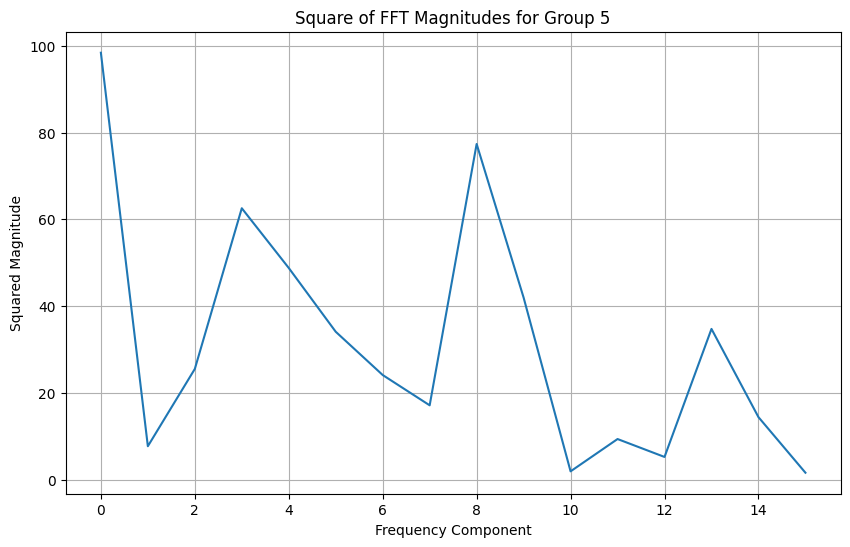

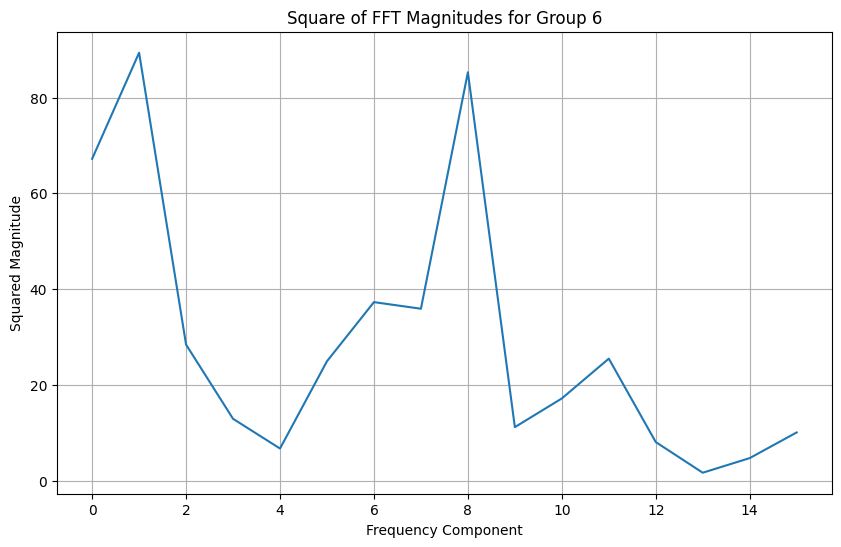

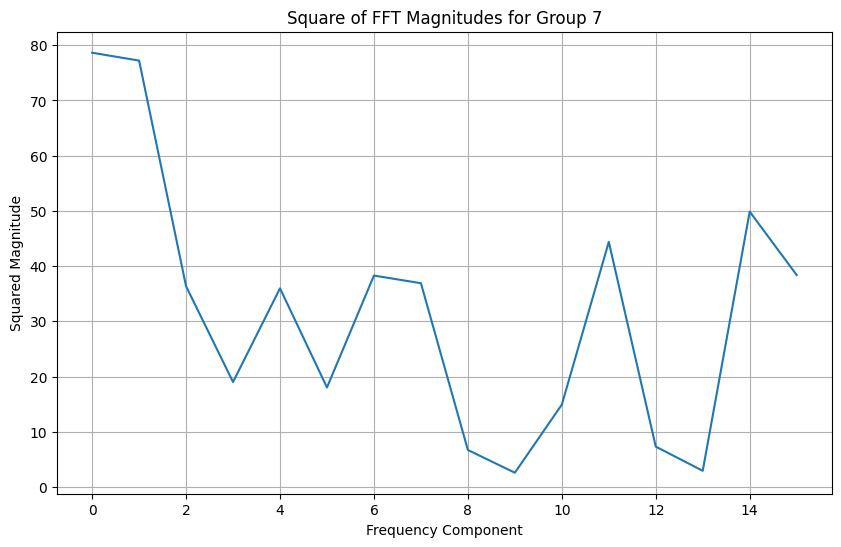

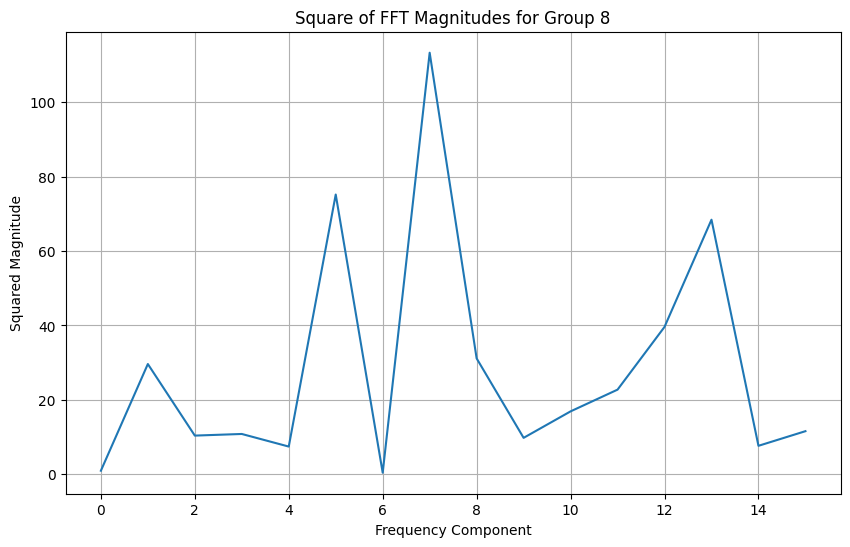

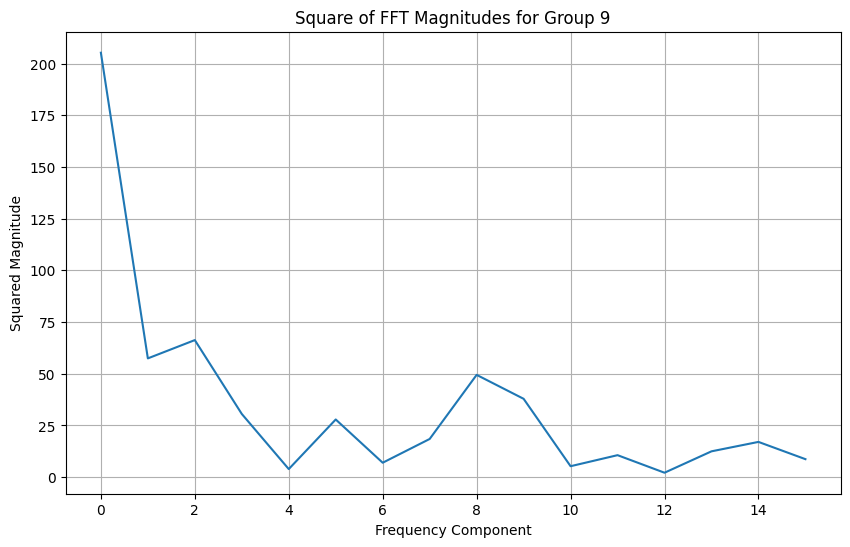

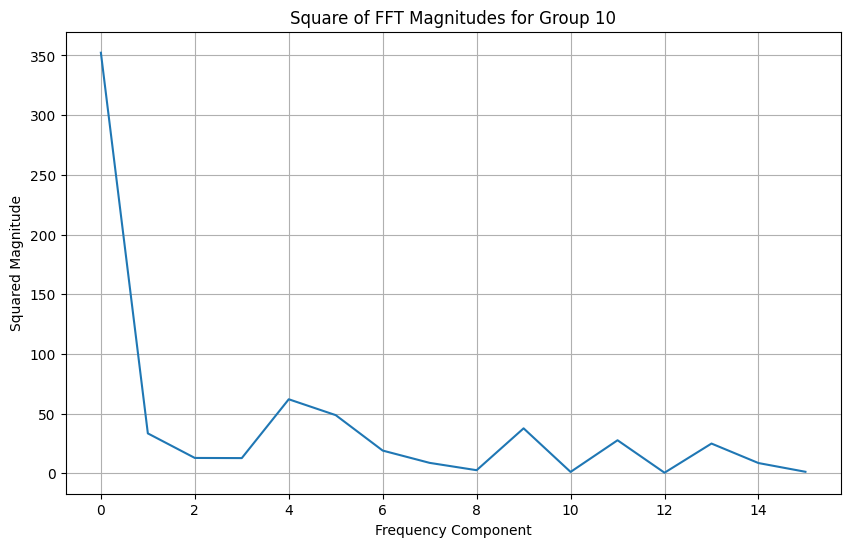

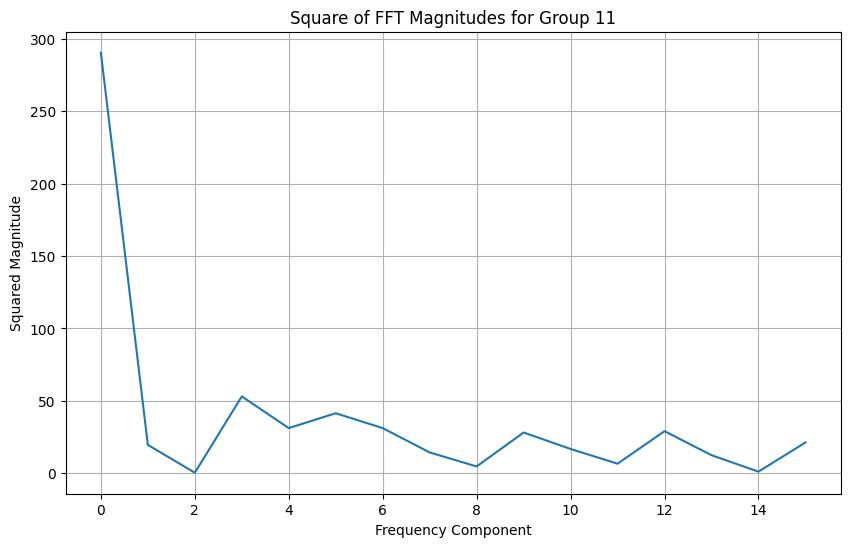

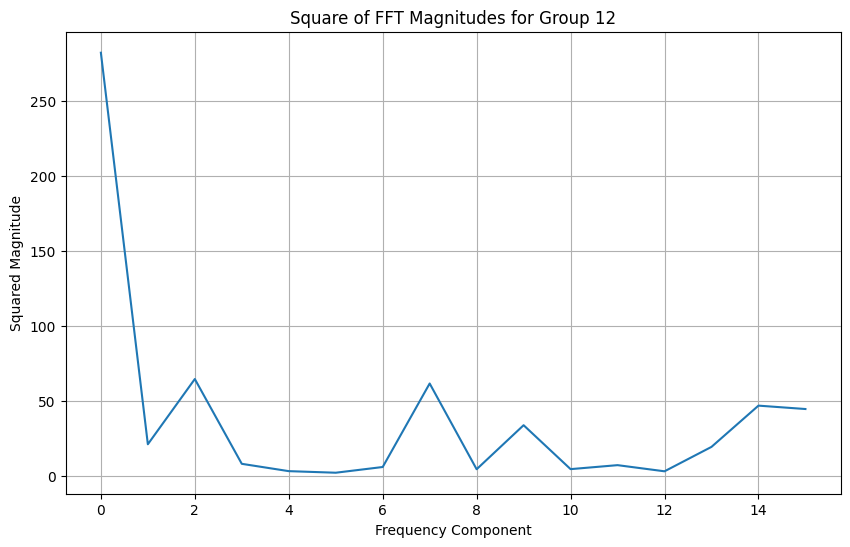

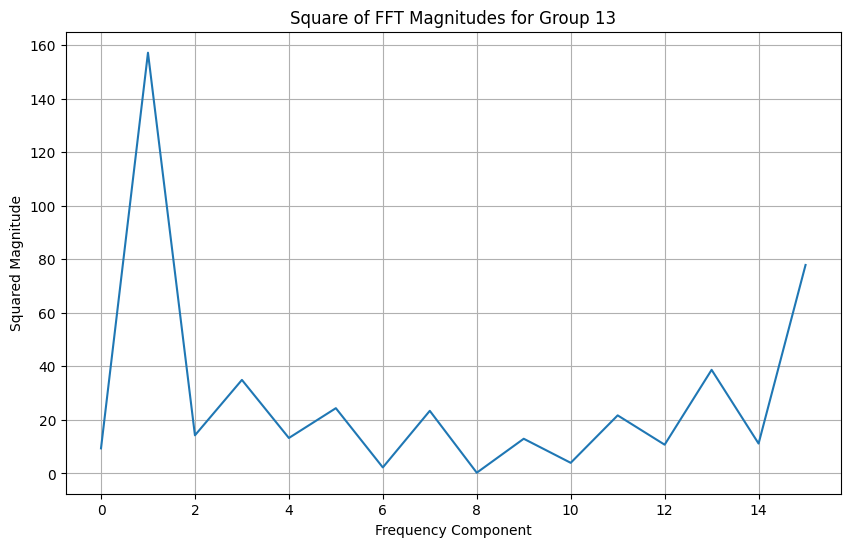

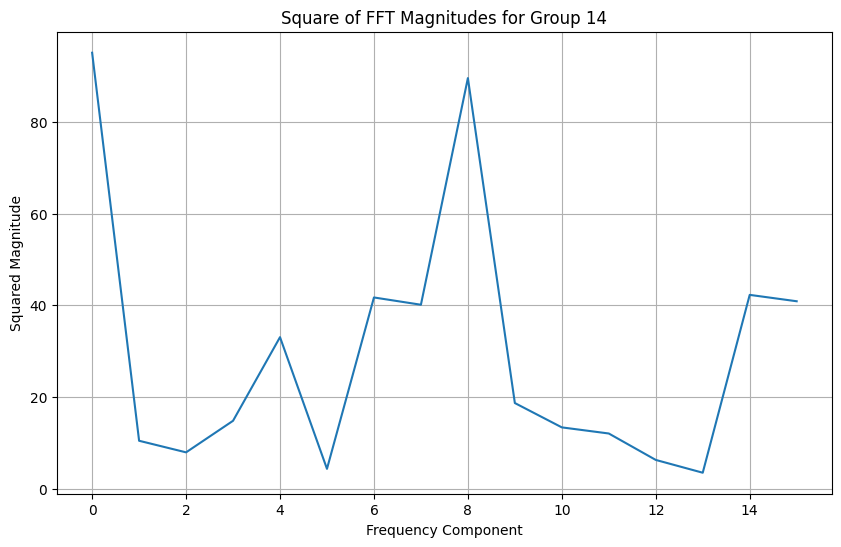

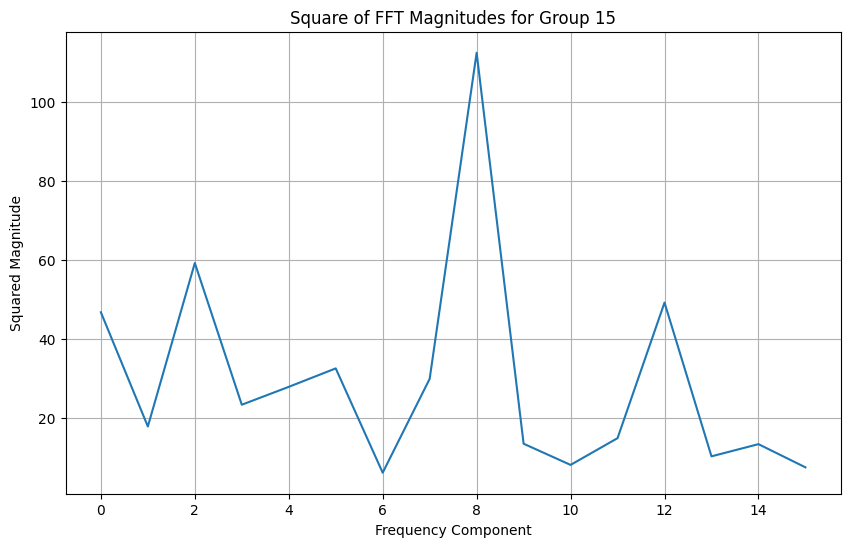

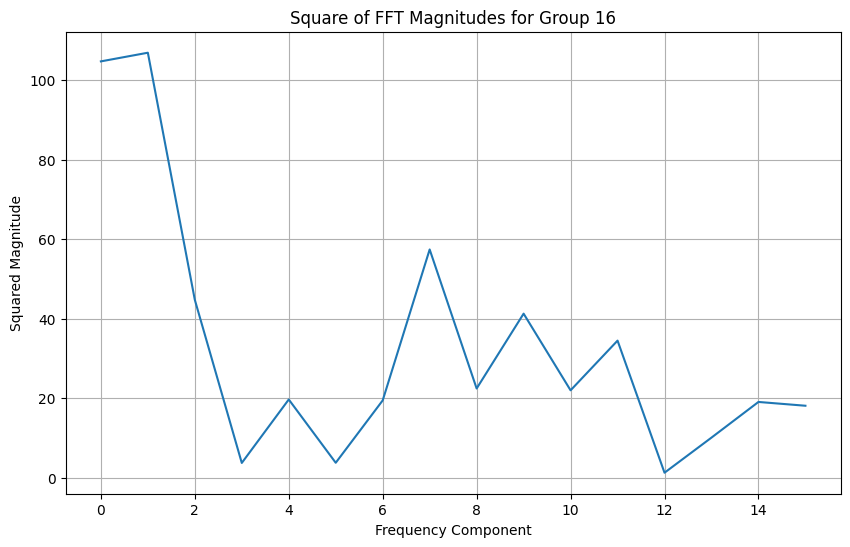

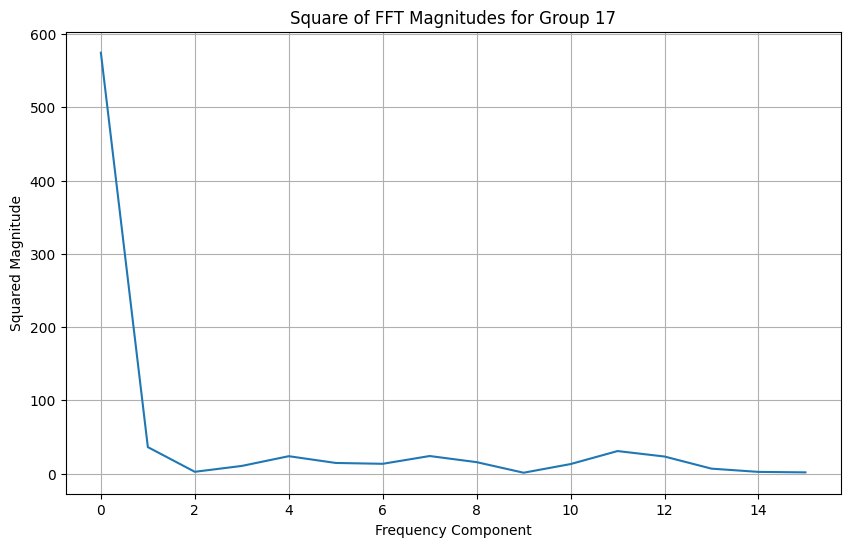

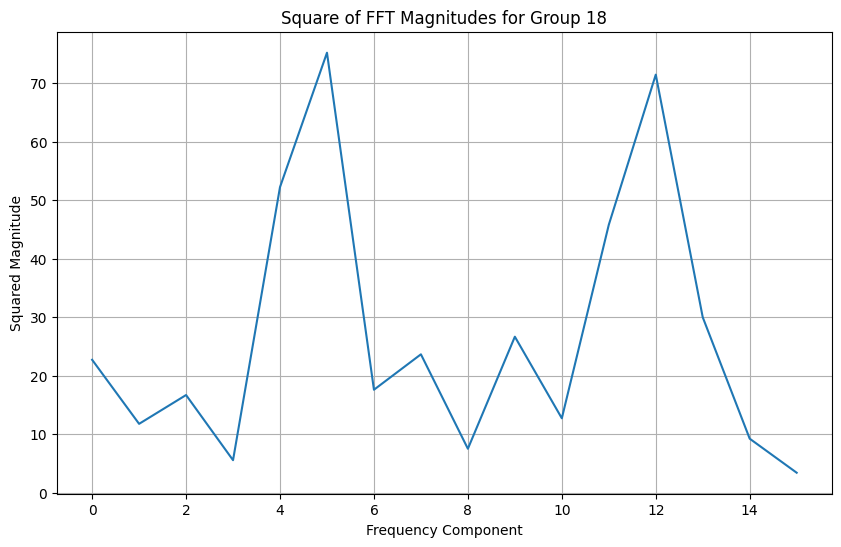

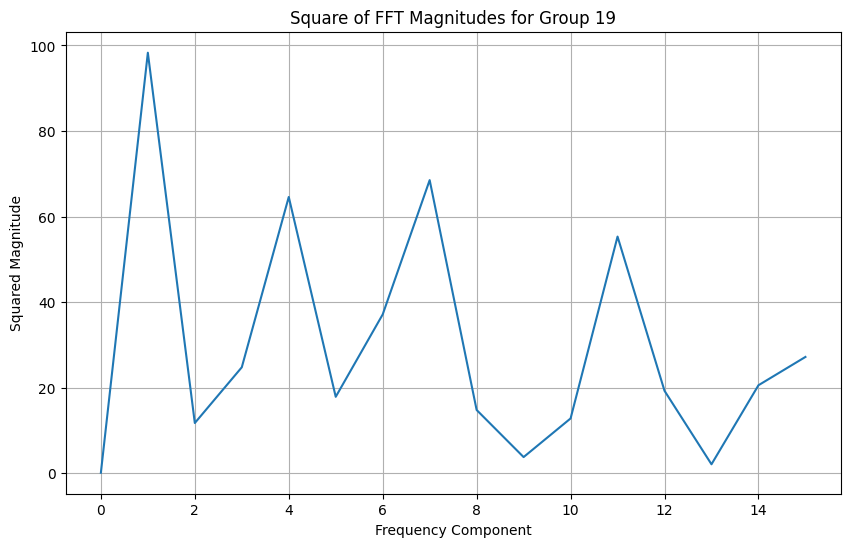

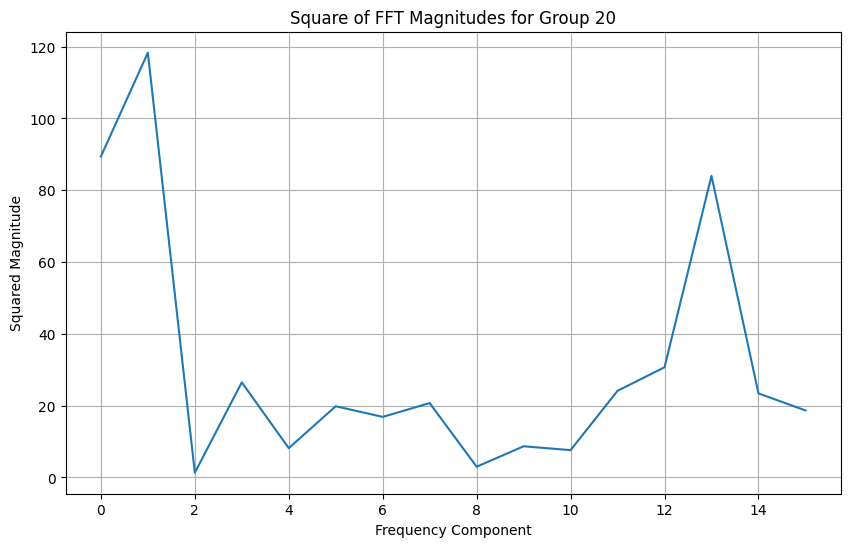

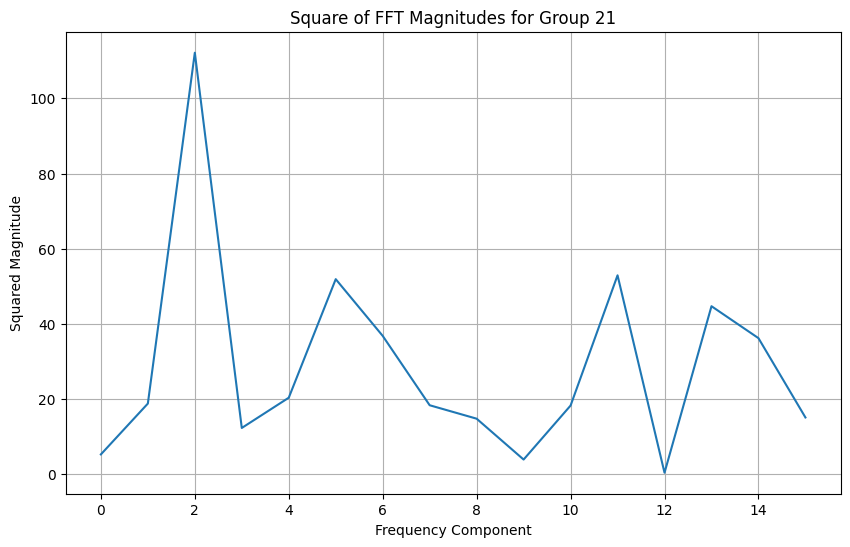

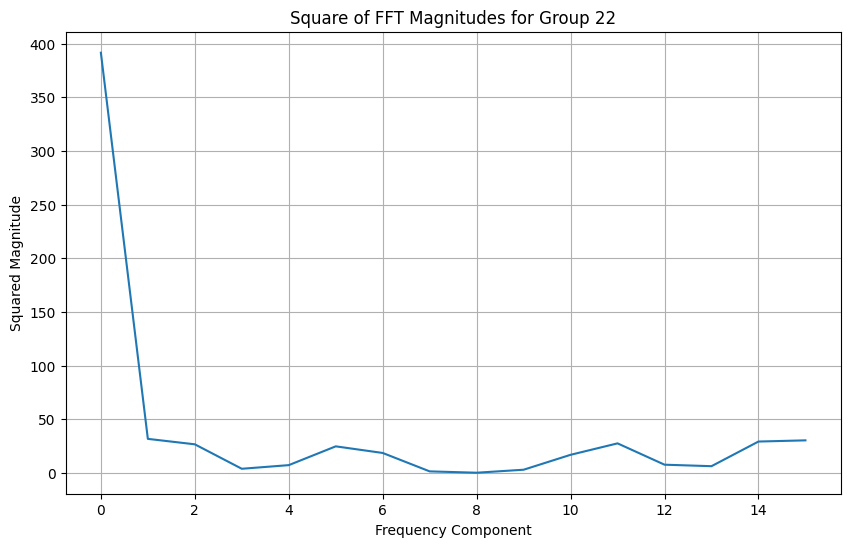

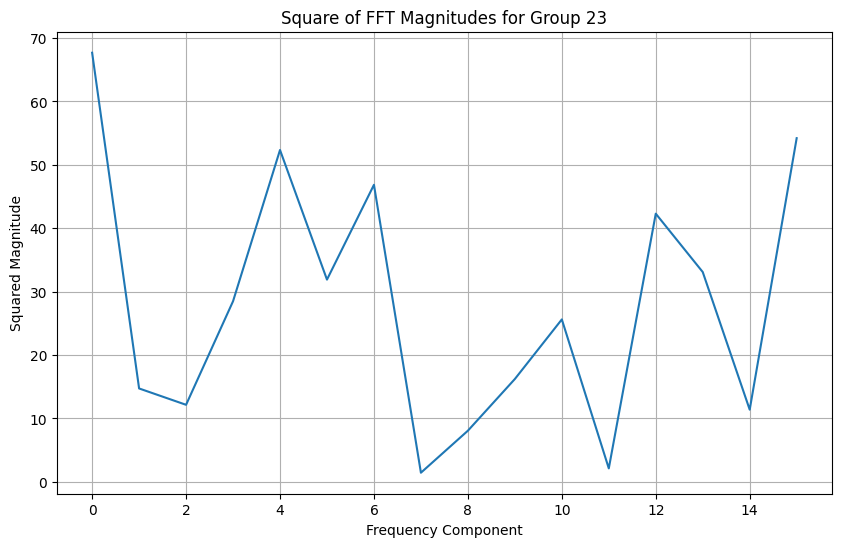

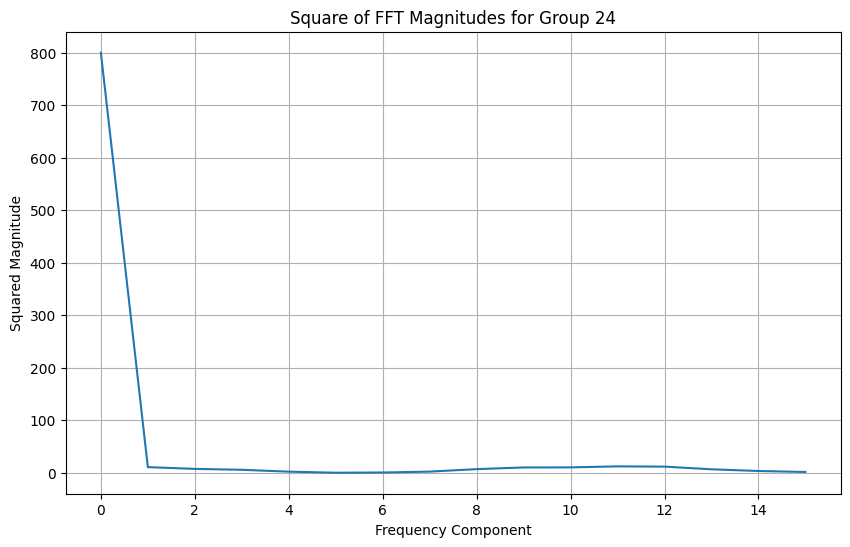

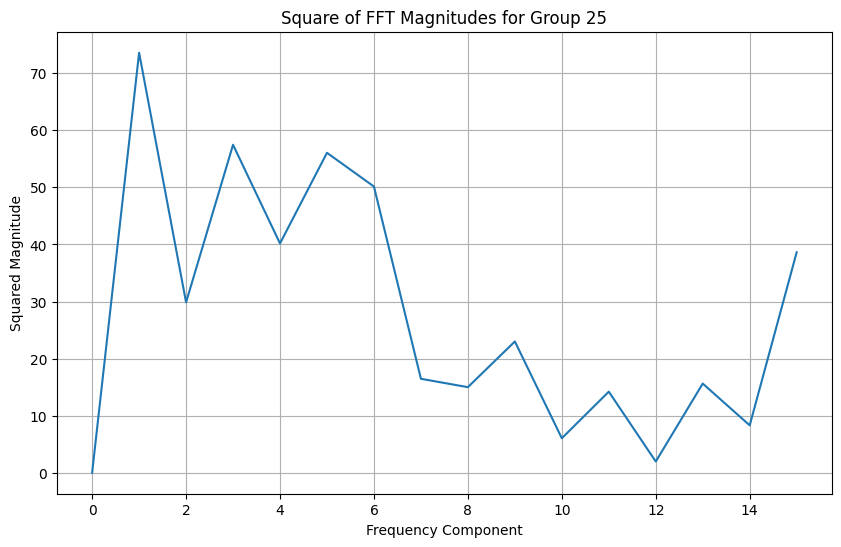

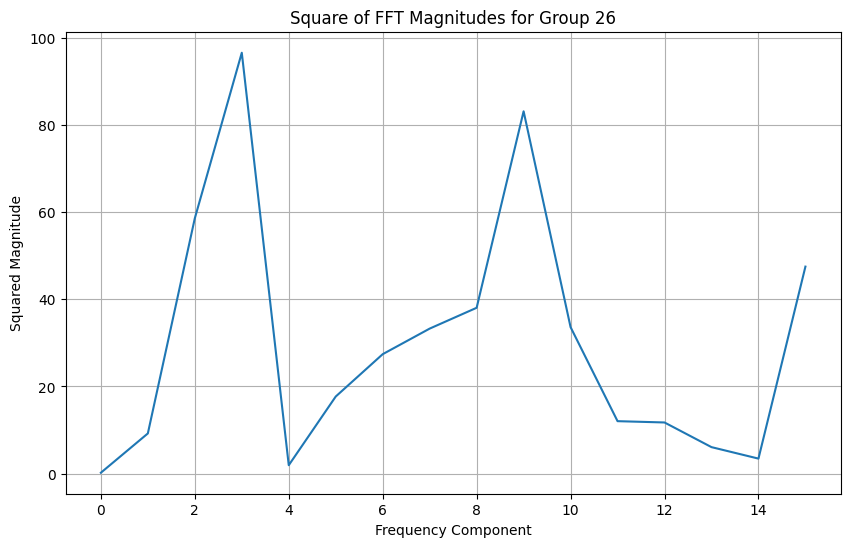

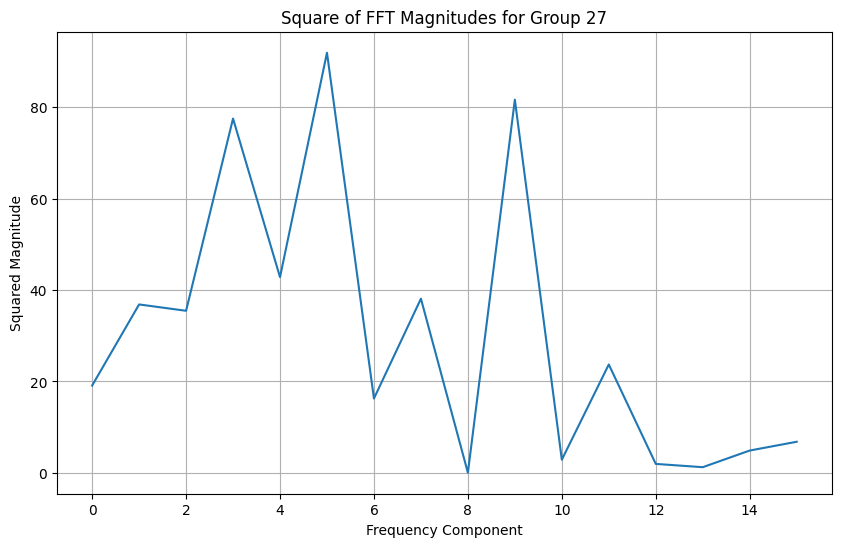

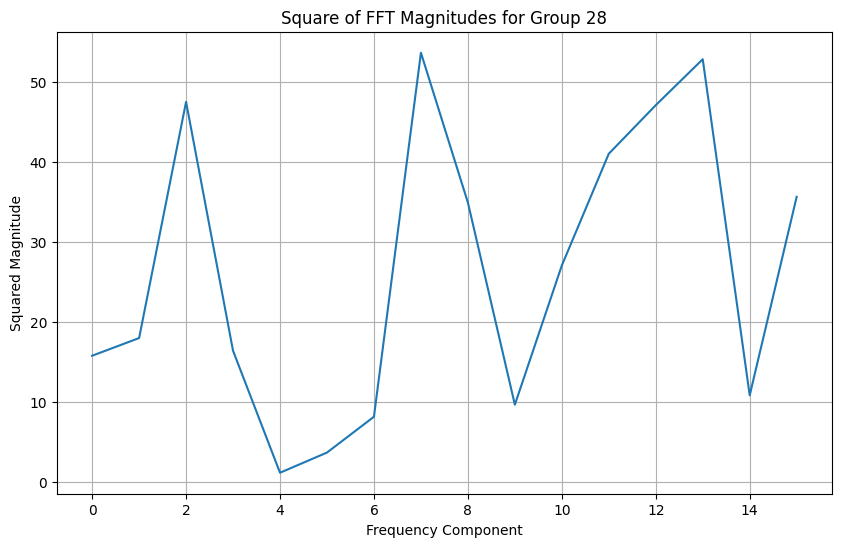

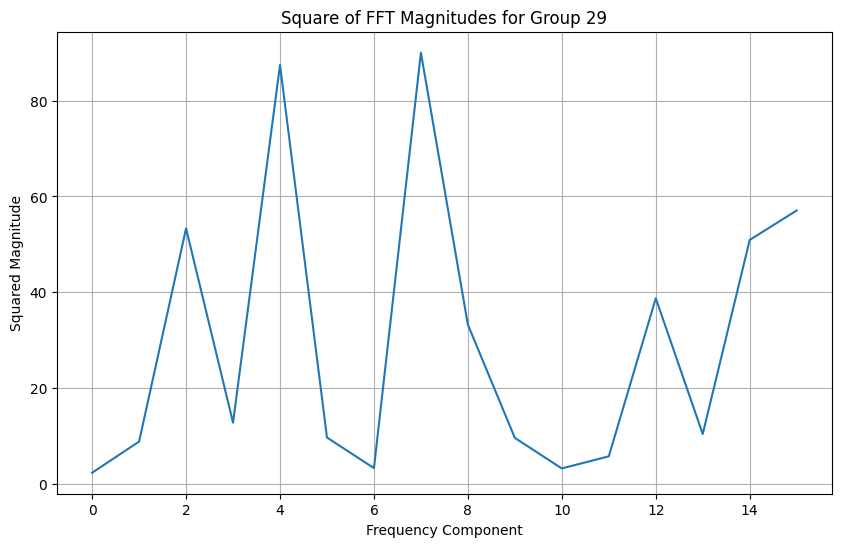

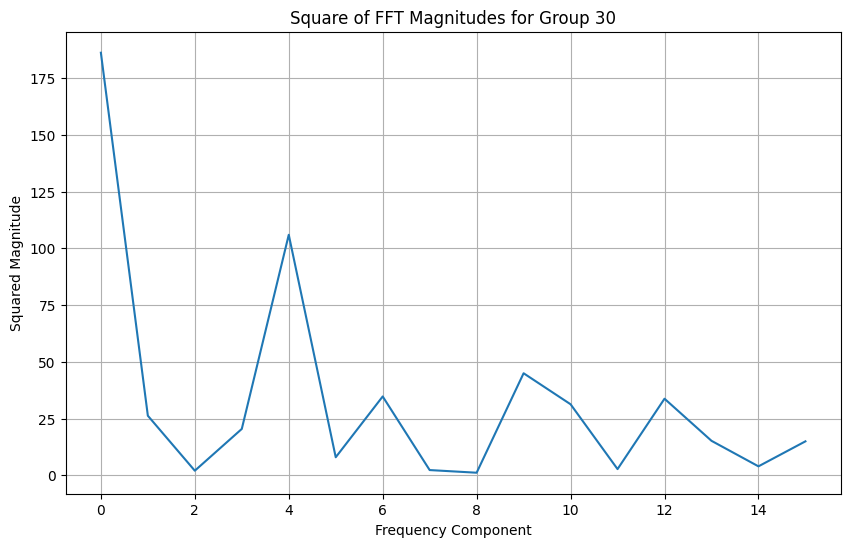

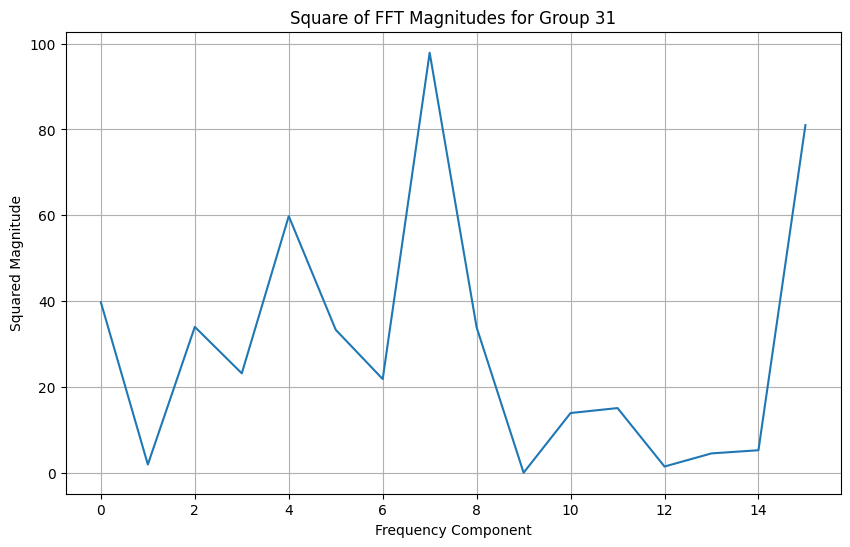

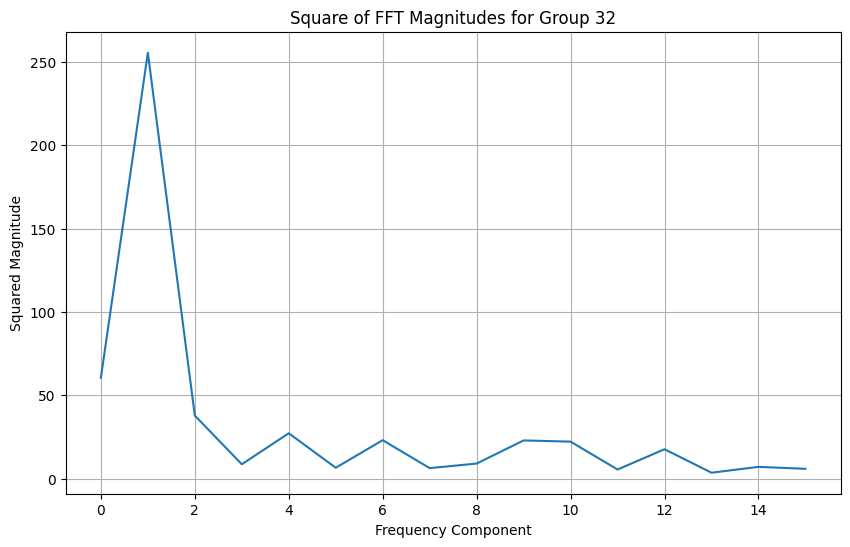

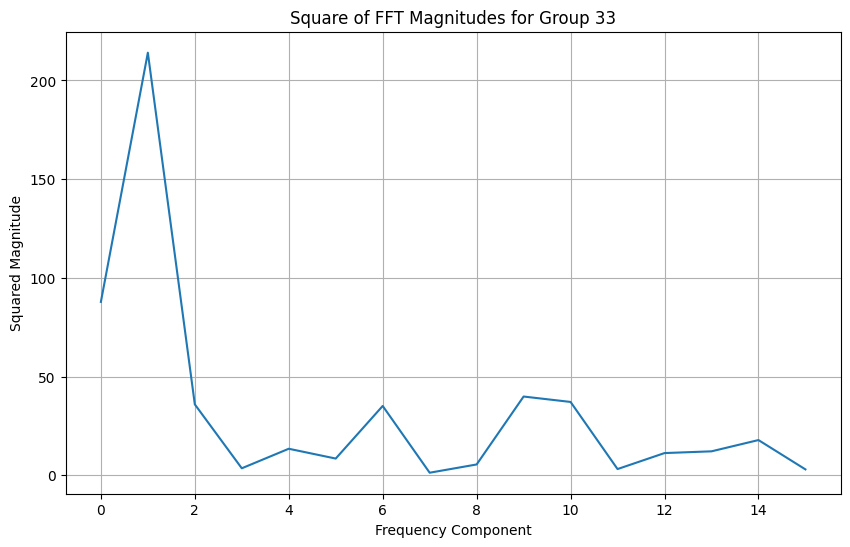

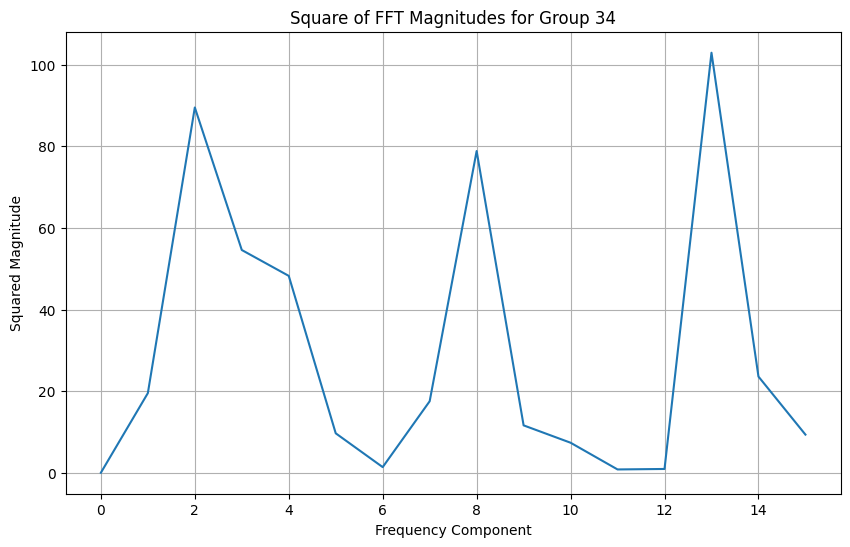

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def plot_fft(dataframe, title):
    fft_result = np.fft.fft(dataframe['sentiment'].values)
    fft_magnitudes = np.abs(fft_result)
    squared_fft_magnitudes = fft_magnitudes[:len(fft_magnitudes)//2] ** 2
    plt.figure(figsize=(10, 6))
    plt.plot(squared_fft_magnitudes)
    plt.title(f'Square of FFT Magnitudes for {title}')
    plt.xlabel('Frequency Component')
    plt.ylabel('Squared Magnitude')
    plt.grid(True)
    plt.show()


for i, df in enumerate(dfs):
    plot_fft(df, f"Group {i+1}")



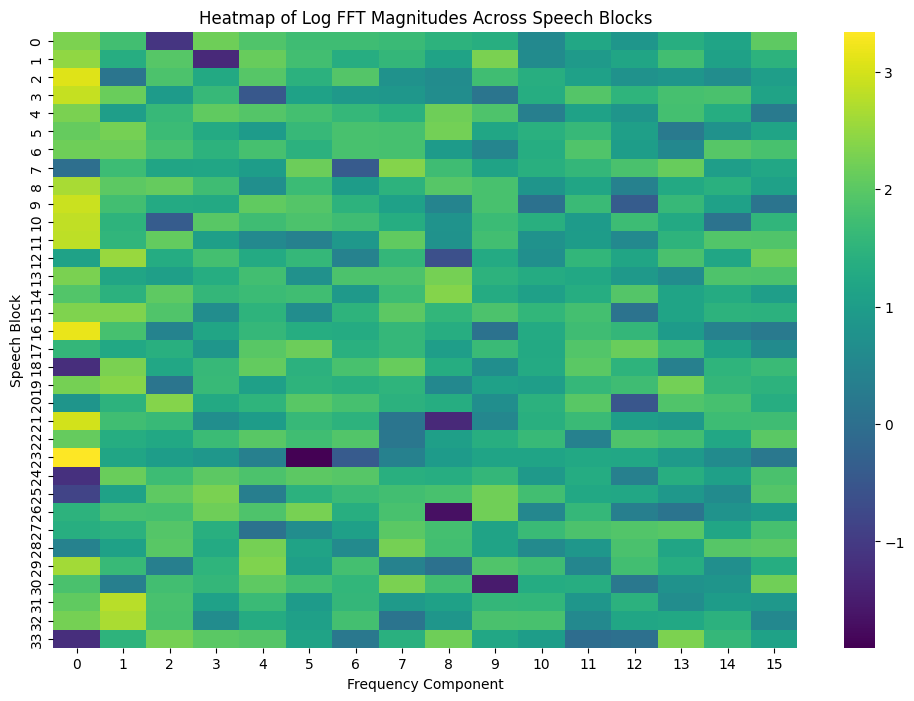

In [5]:
import numpy as np

def compute_log_fft_magnitudes(dataframe):
    fft_result = np.fft.fft(dataframe['sentiment'].values)
    fft_magnitudes = np.abs(fft_result)
    log_fft_magnitudes = np.log(fft_magnitudes[:len(fft_magnitudes)//2] + 1e-9)
    
    return log_fft_magnitudes
log_fft_magnitudes_list = [compute_log_fft_magnitudes(df) for df in dfs]
log_fft_magnitudes_matrix = np.vstack(log_fft_magnitudes_list)
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
sns.heatmap(log_fft_magnitudes_matrix, cmap='viridis', cbar=True)
plt.title('Heatmap of Log FFT Magnitudes Across Speech Blocks')
plt.xlabel('Frequency Component')
plt.ylabel('Speech Block')
plt.show()


In [1]:
dfs = []


grouped = dataset.groupby('Title')
for _, group in grouped:
    num_chunks = len(group) // 16
    

    for i in range(num_chunks):
        chunk = group.iloc[i*16:(i+1)*16]
        dfs.append(chunk)
        print(chunk)


NameError: name 'dataset' is not defined

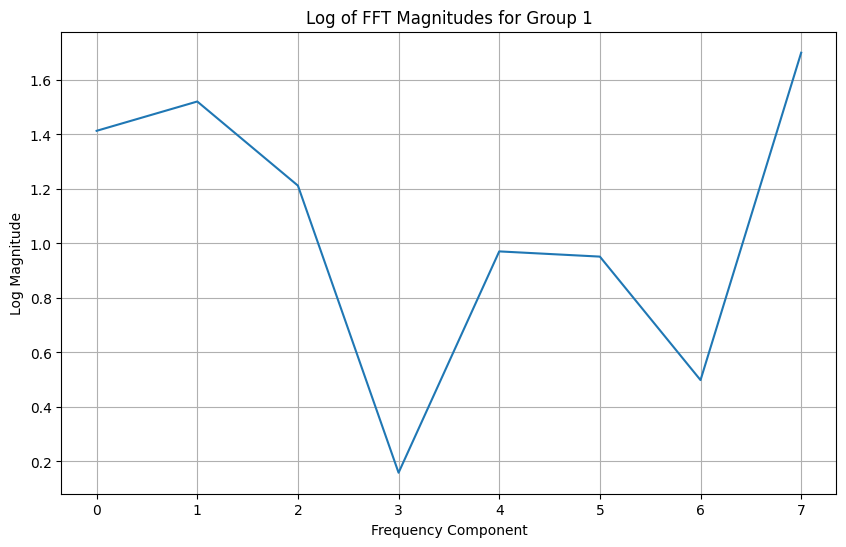

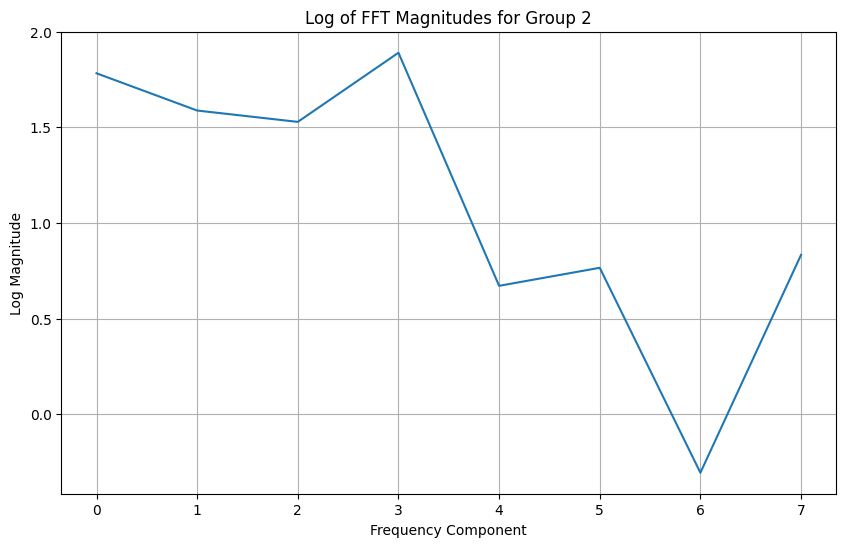

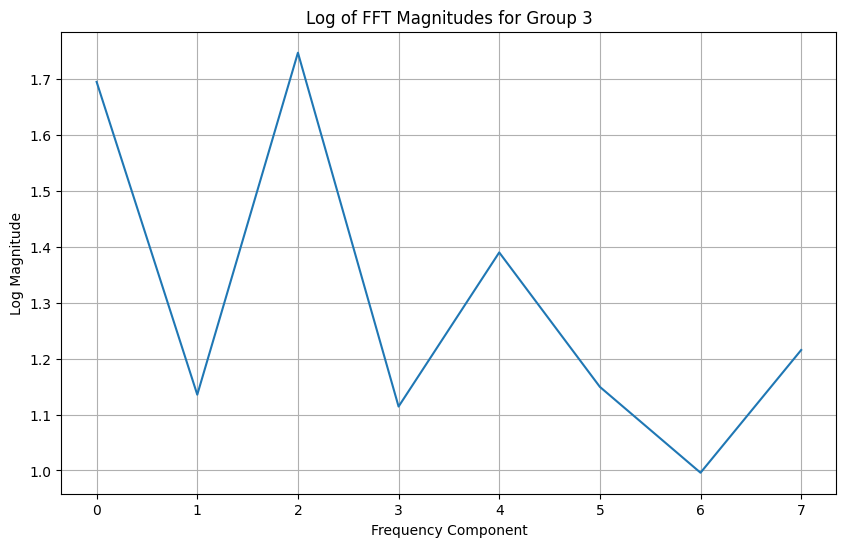

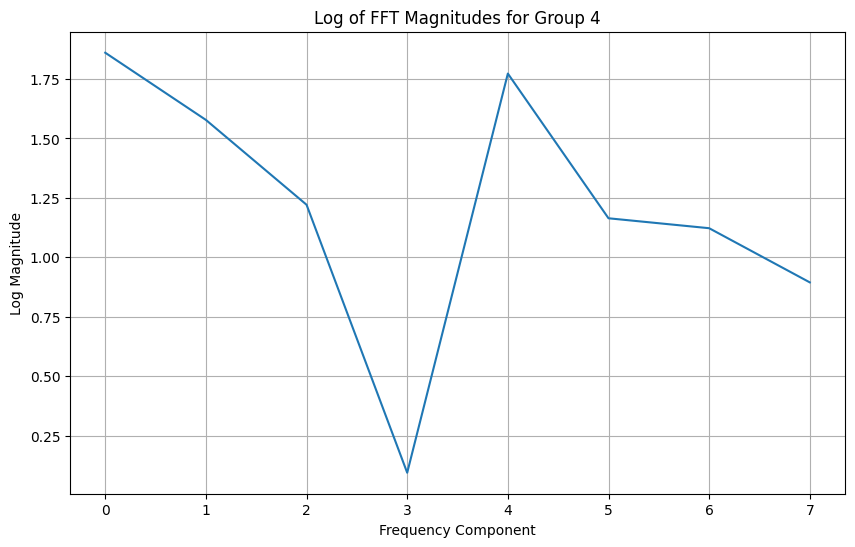

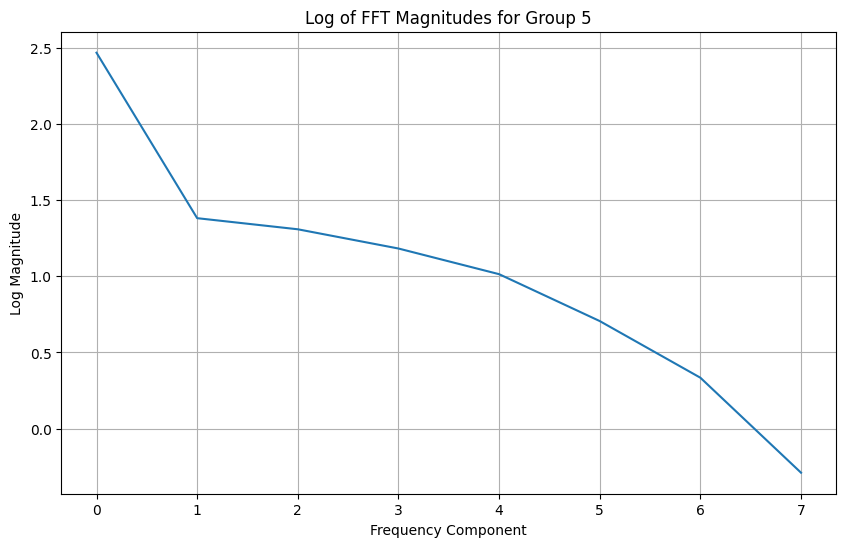

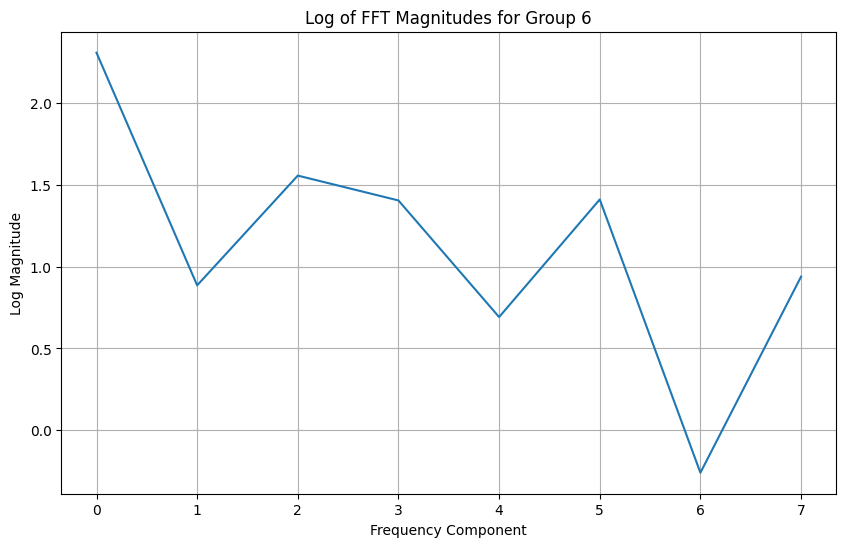

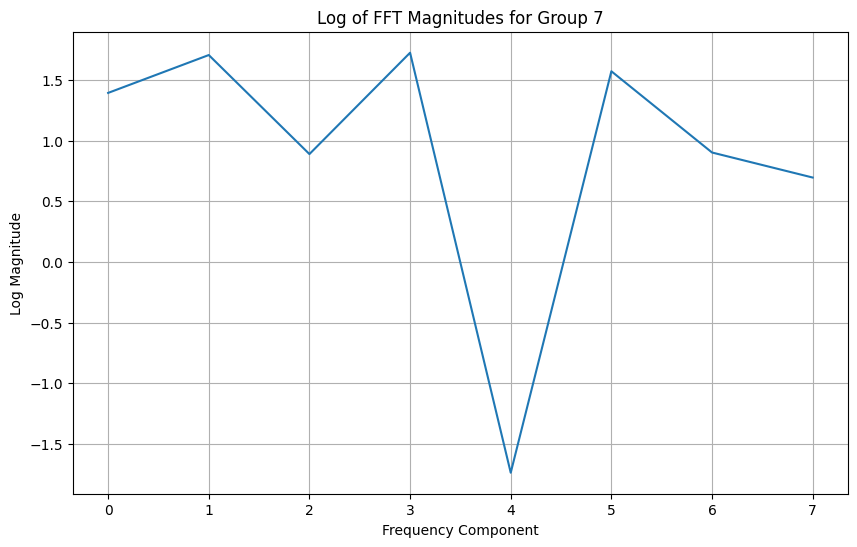

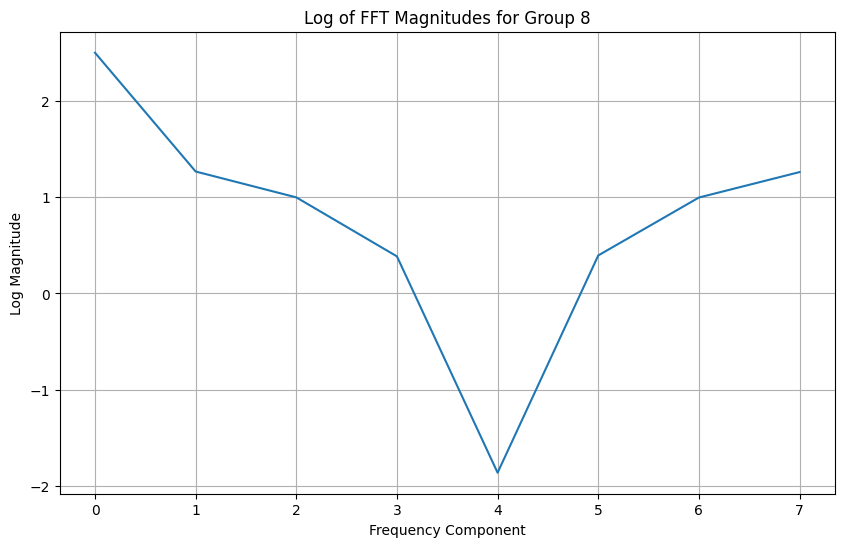

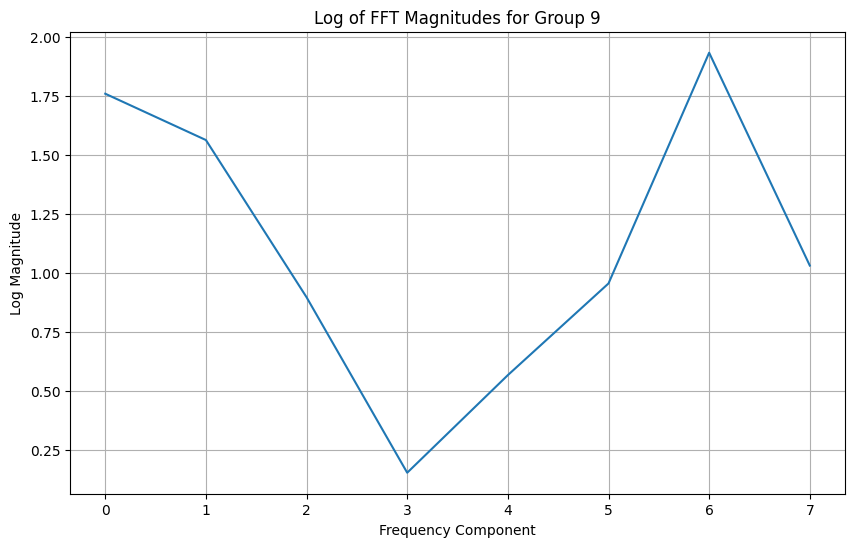

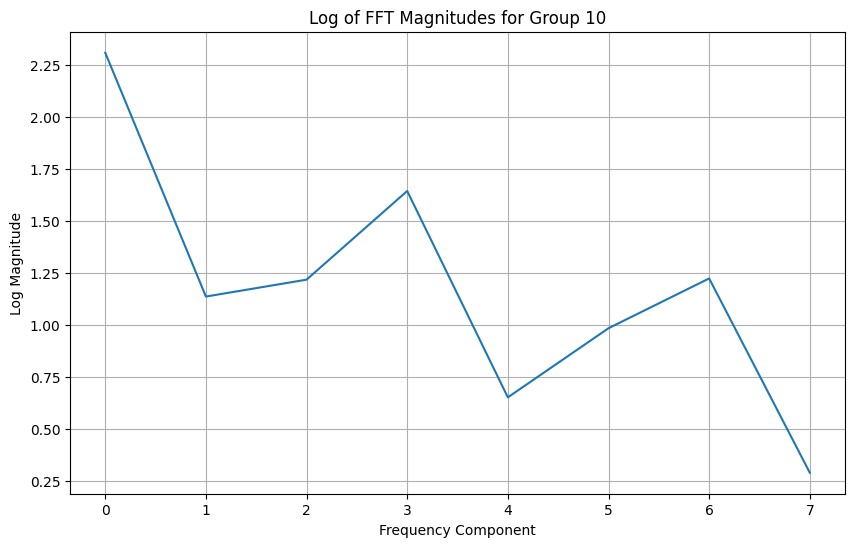

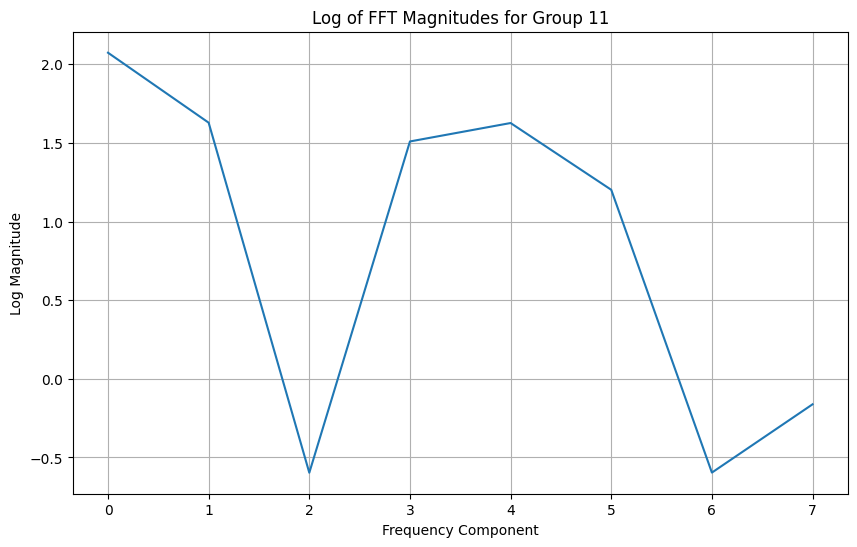

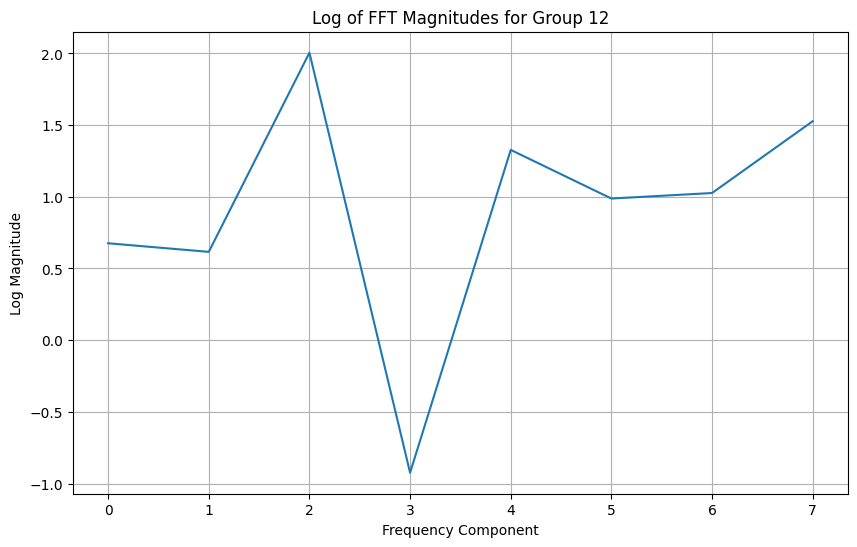

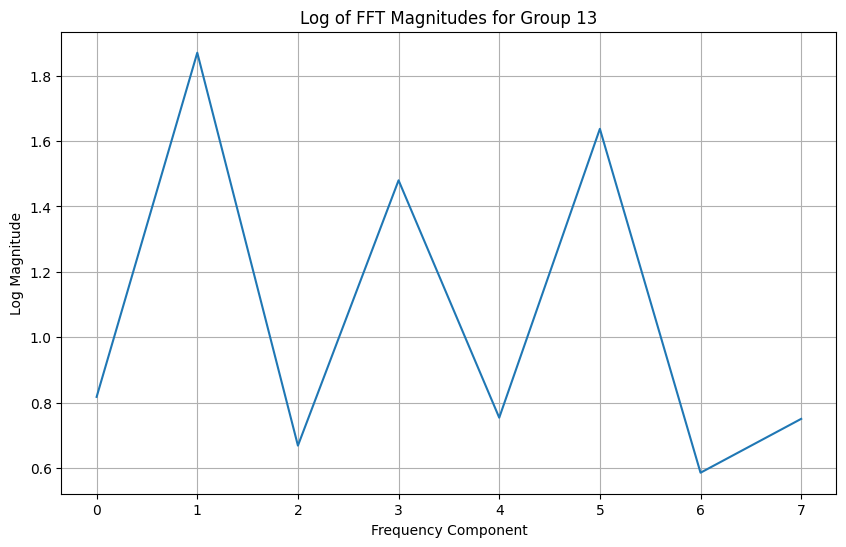

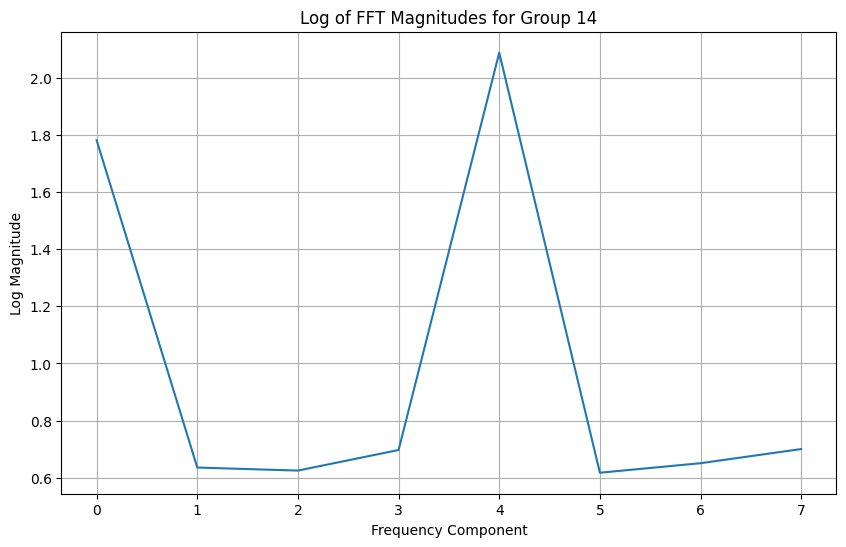

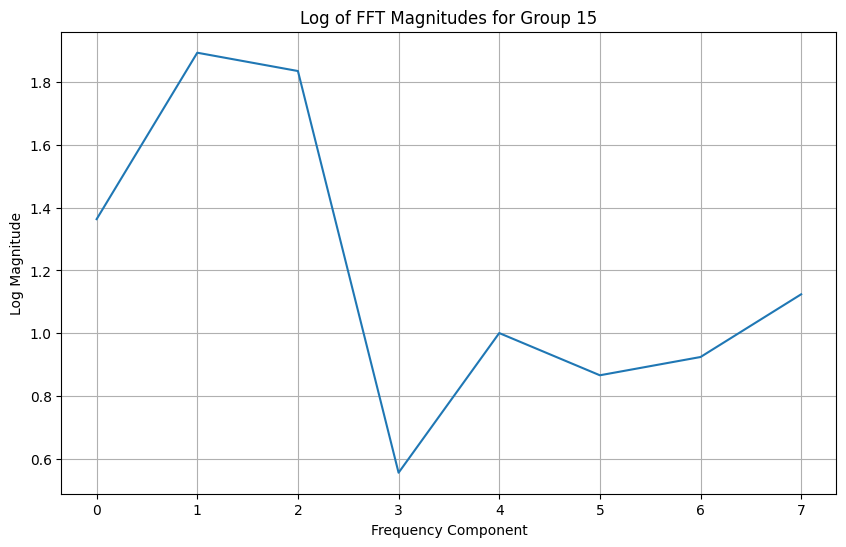

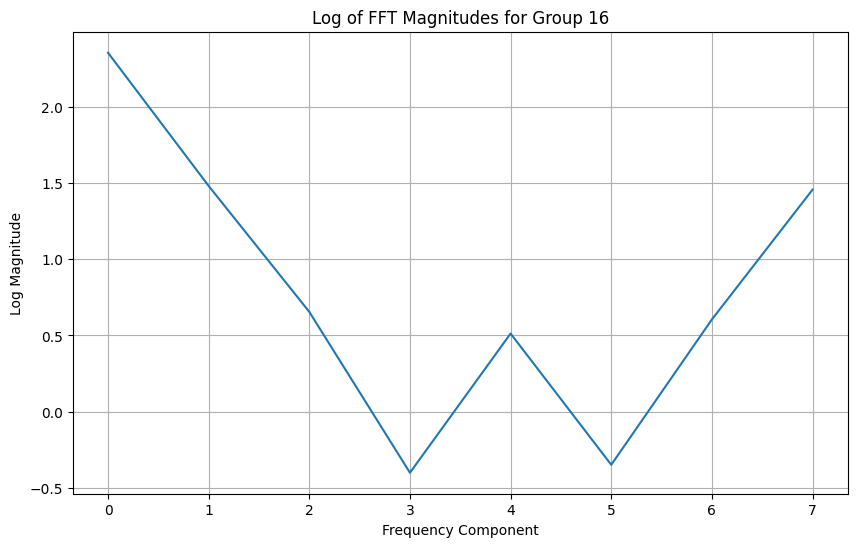

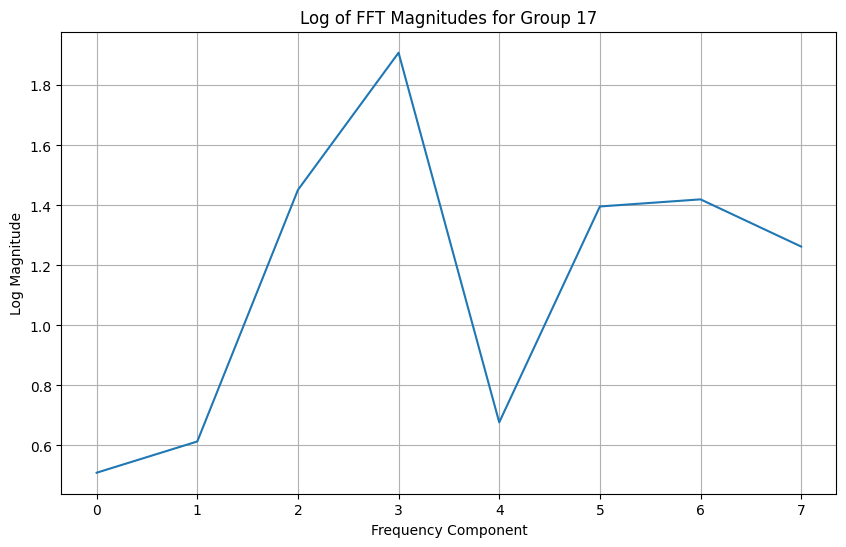

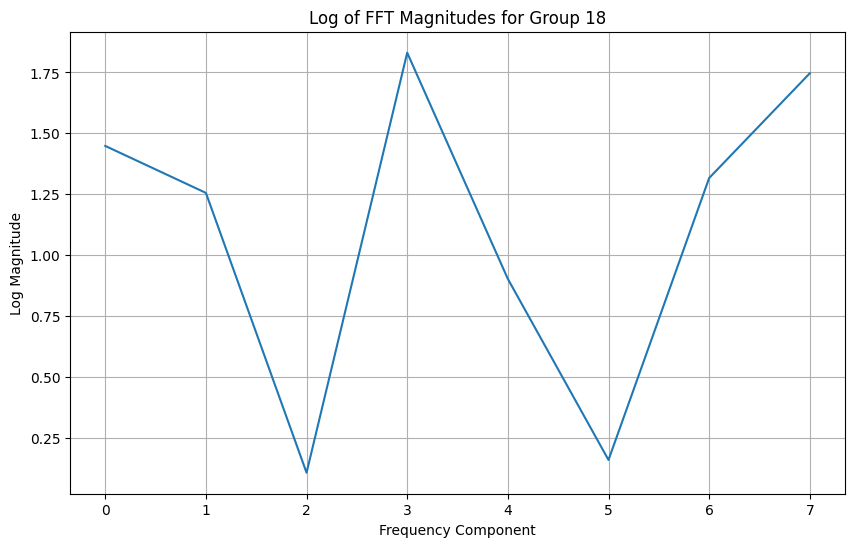

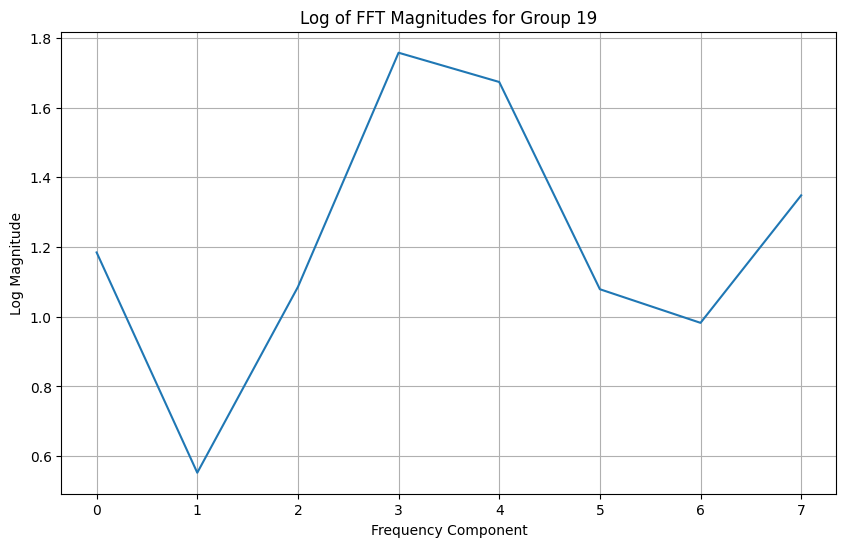

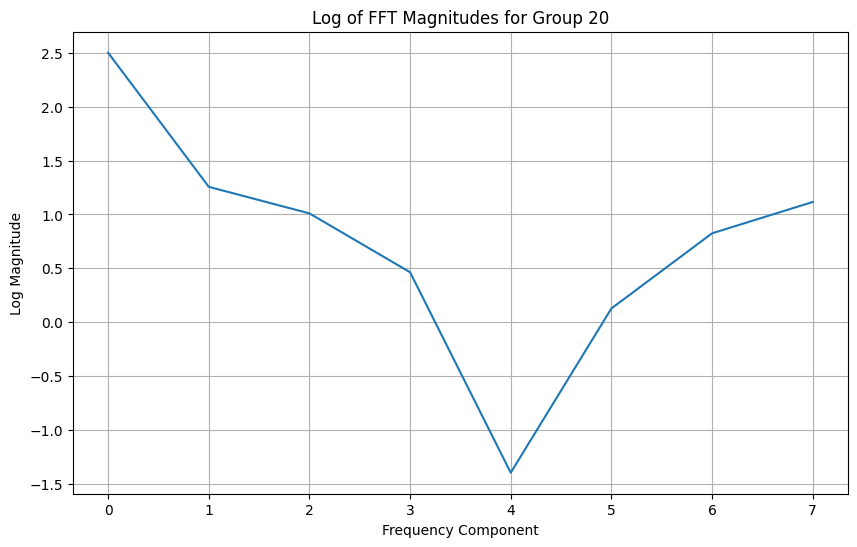

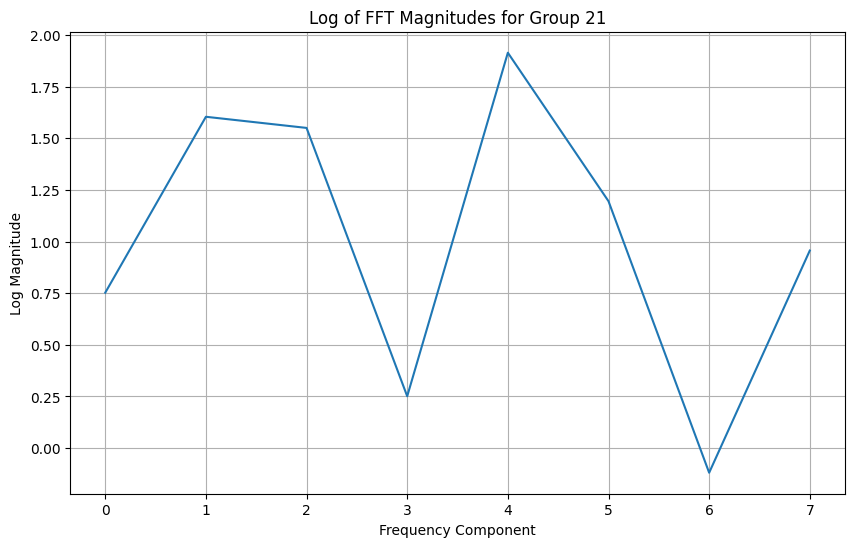

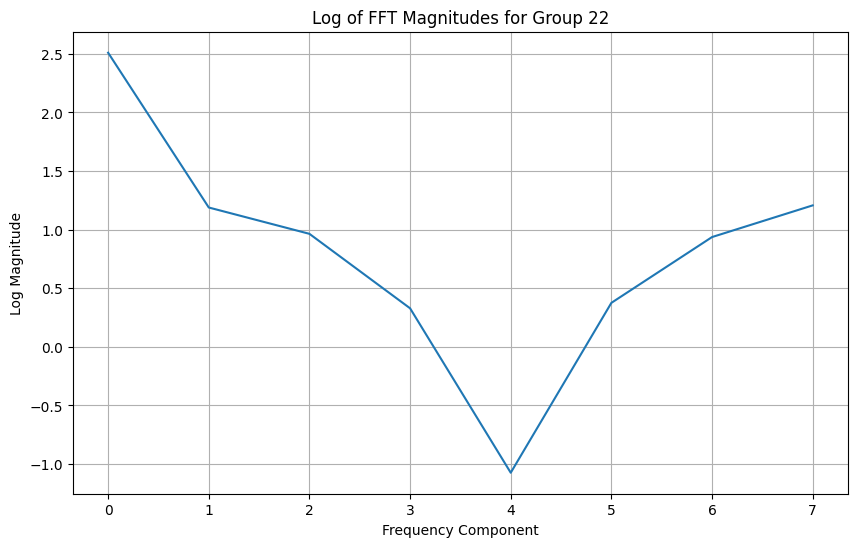

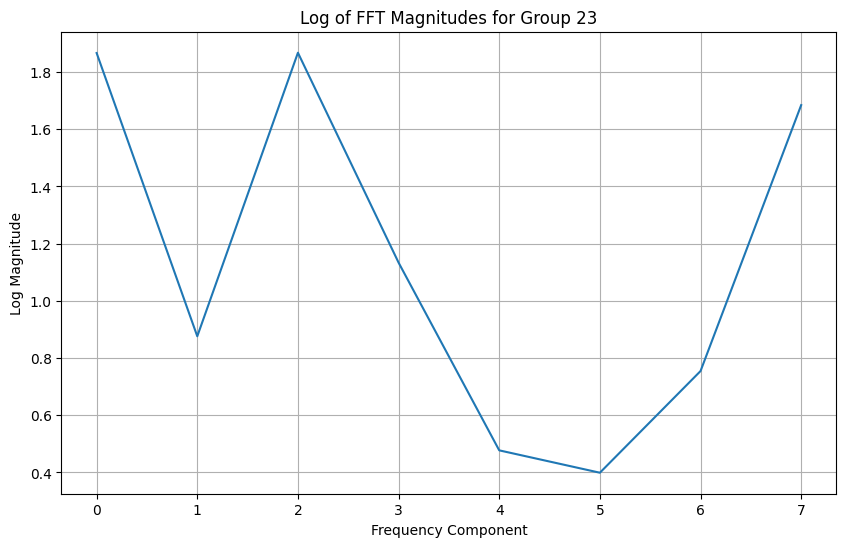

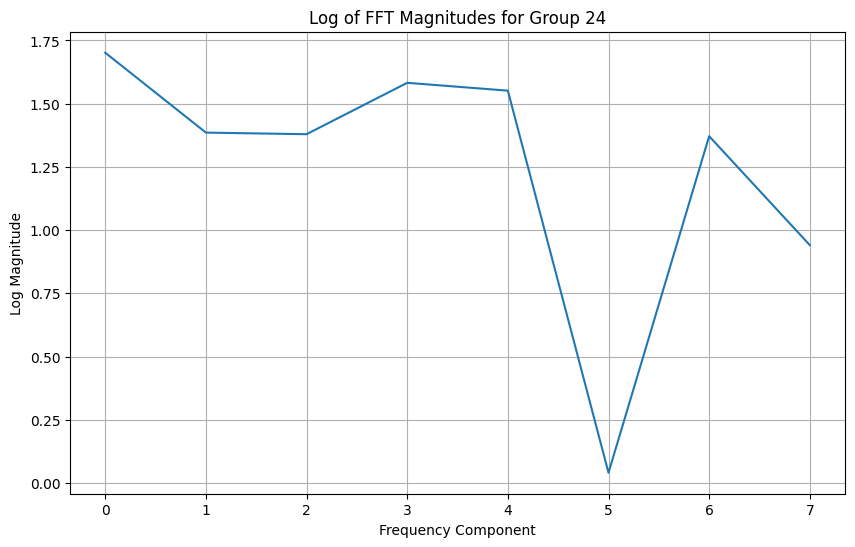

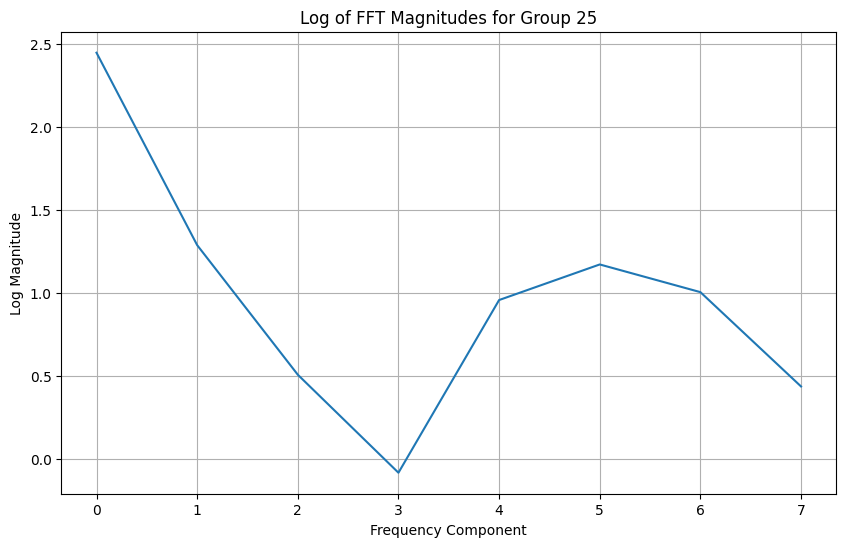

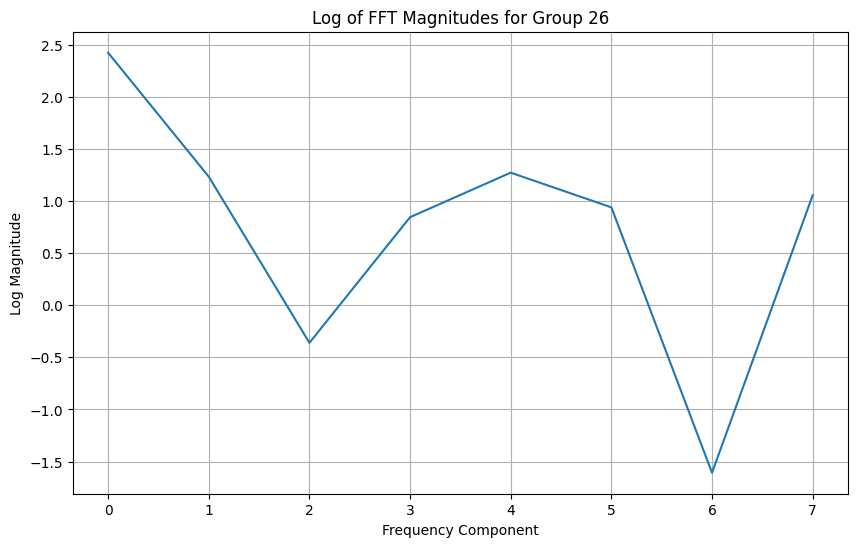

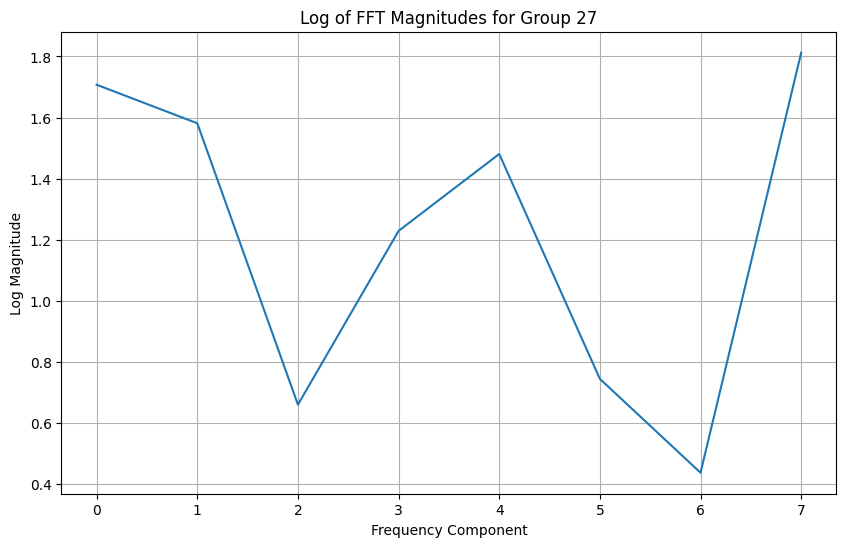

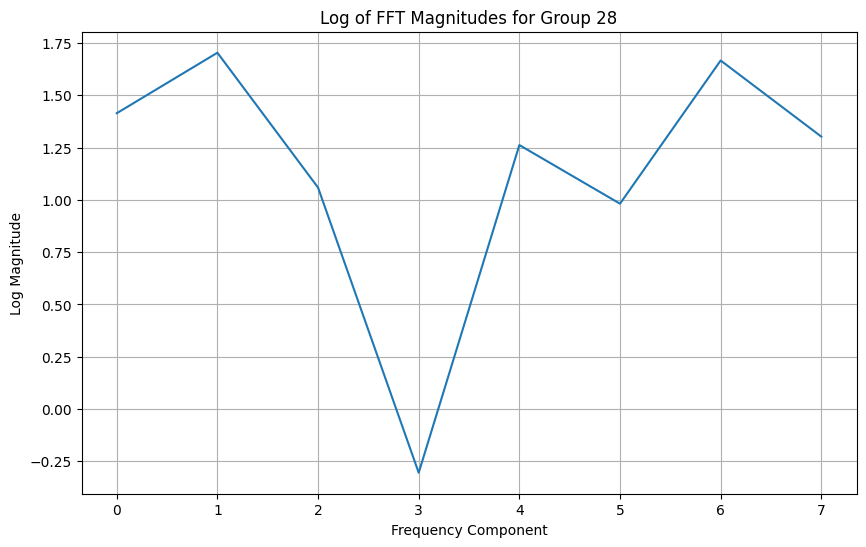

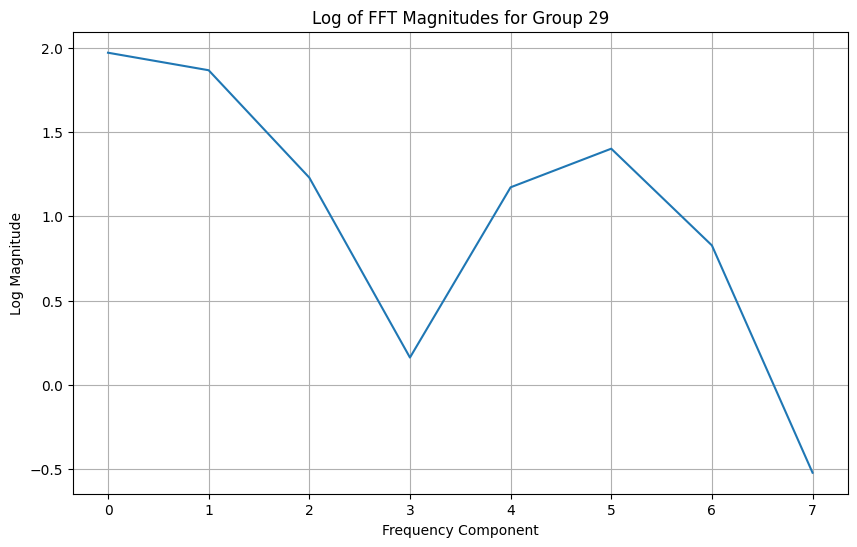

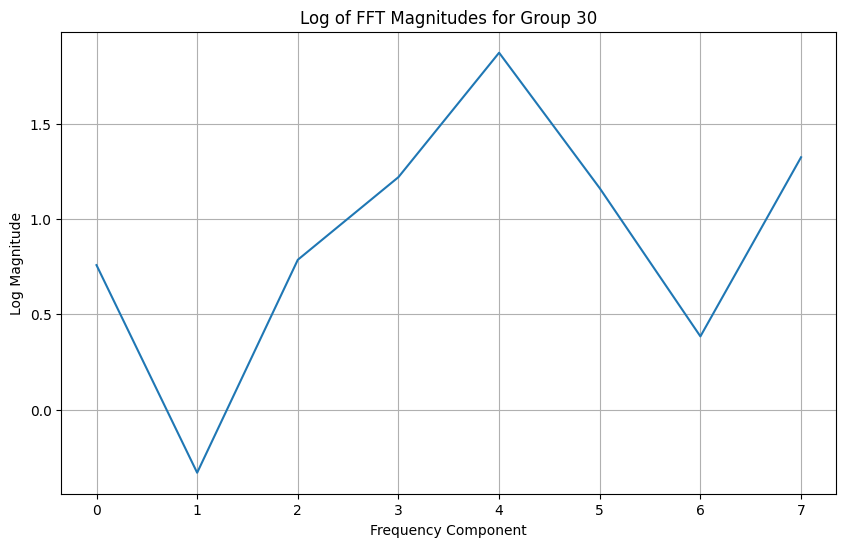

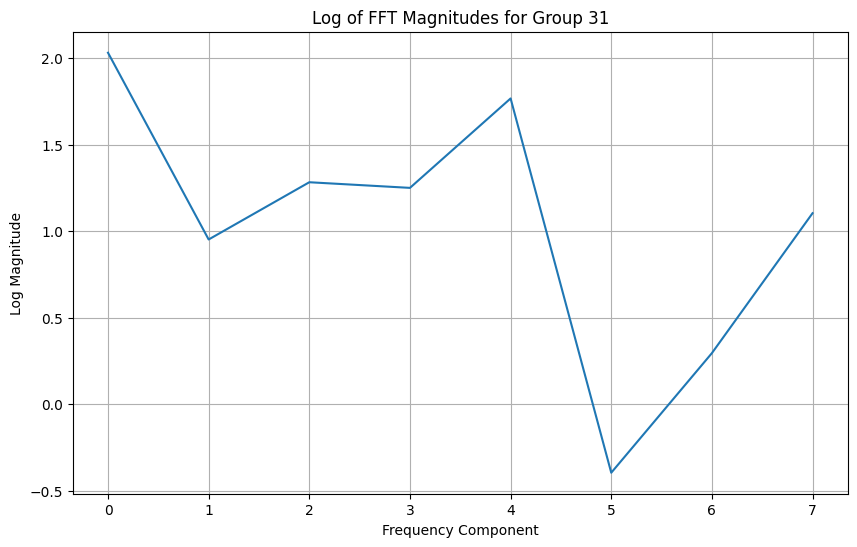

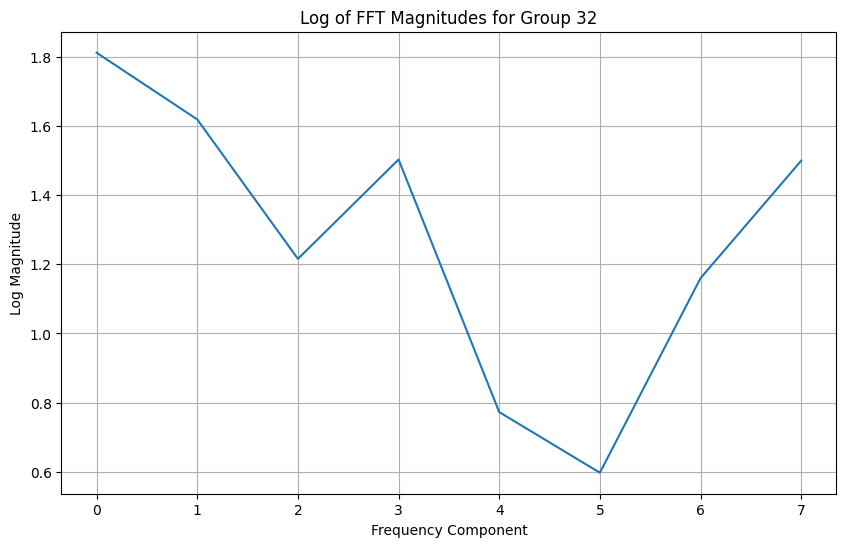

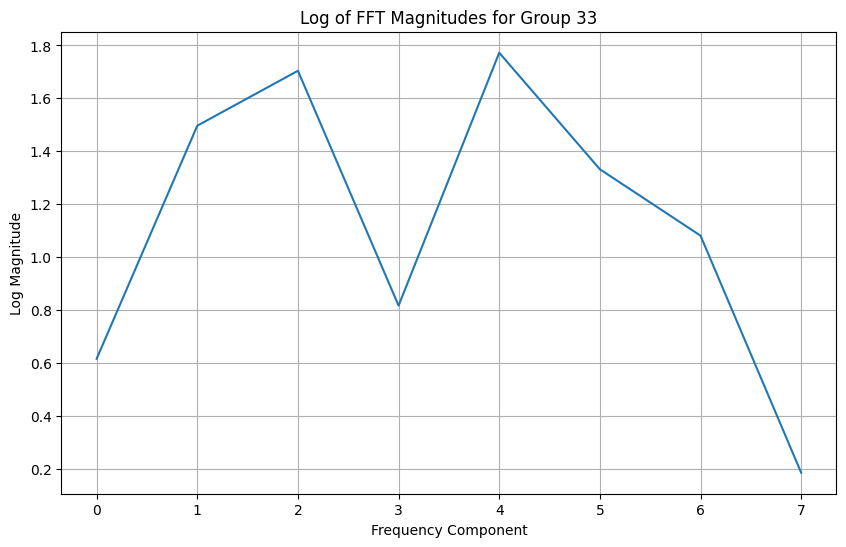

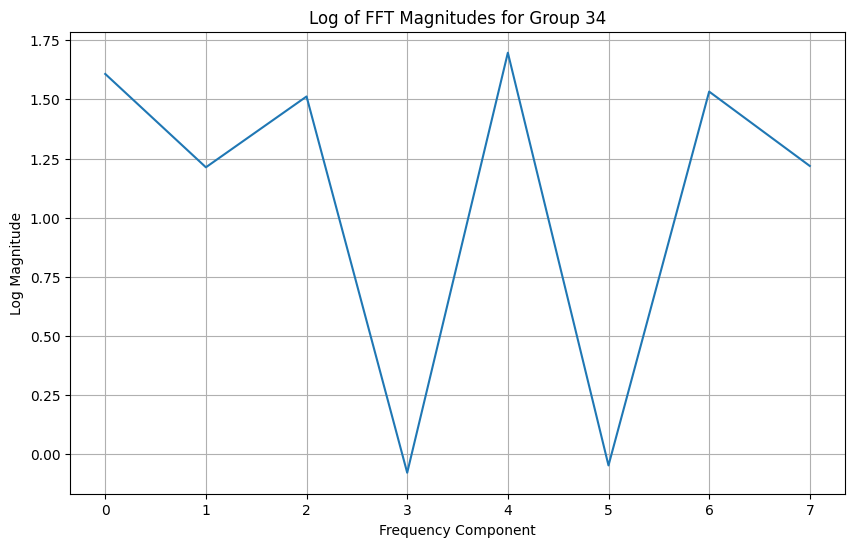

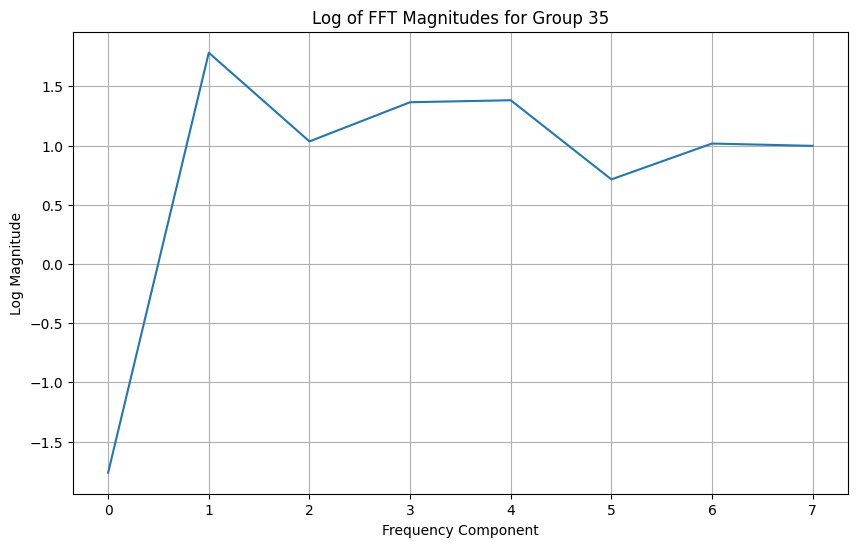

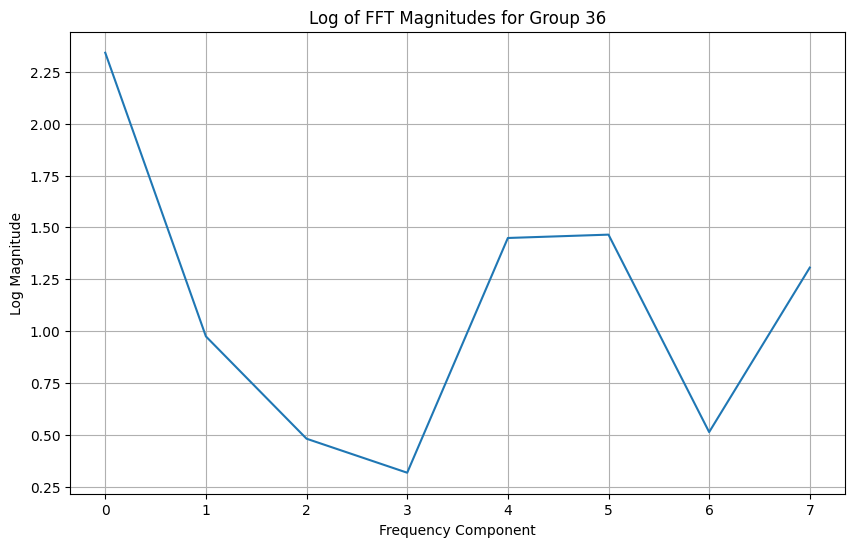

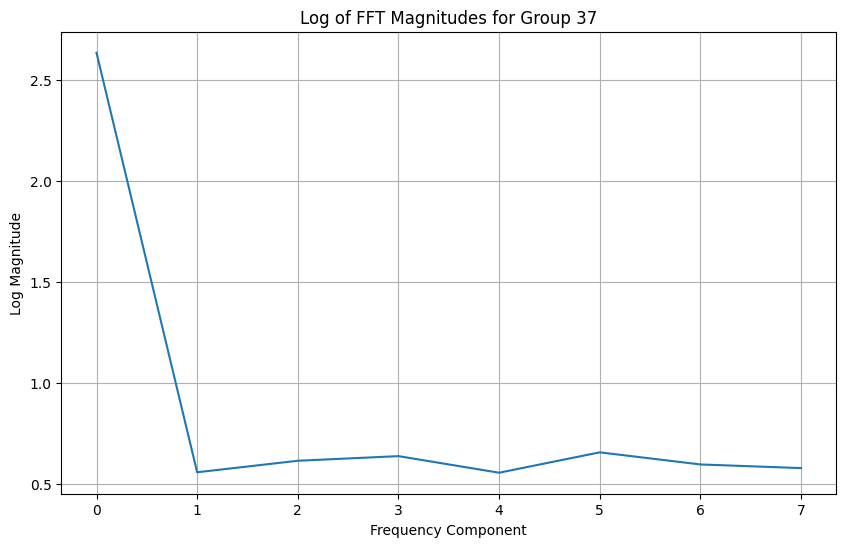

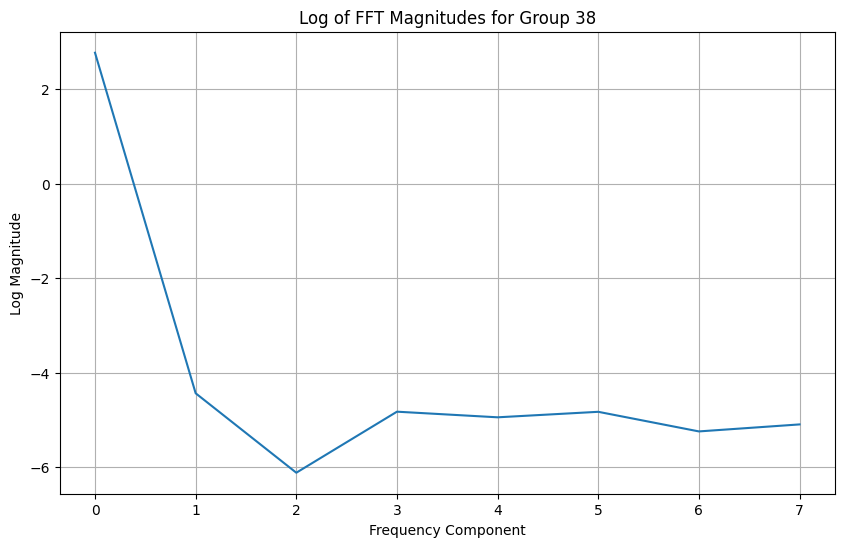

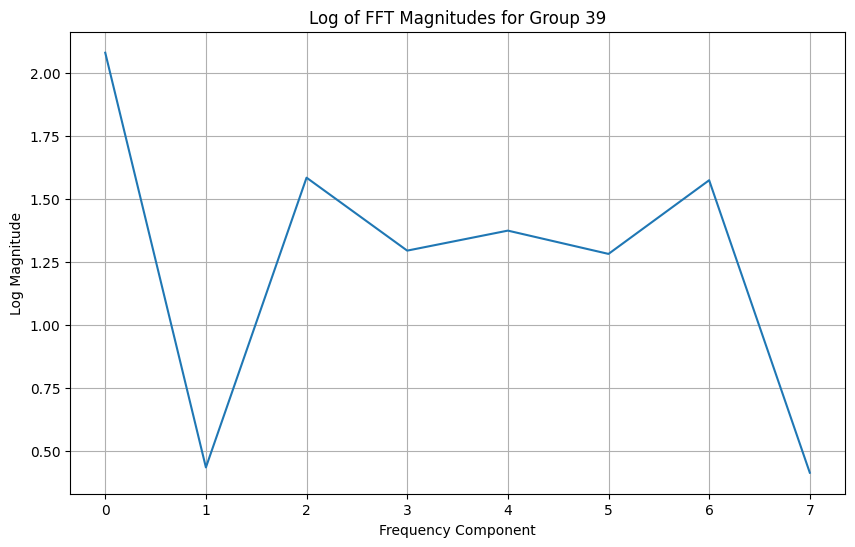

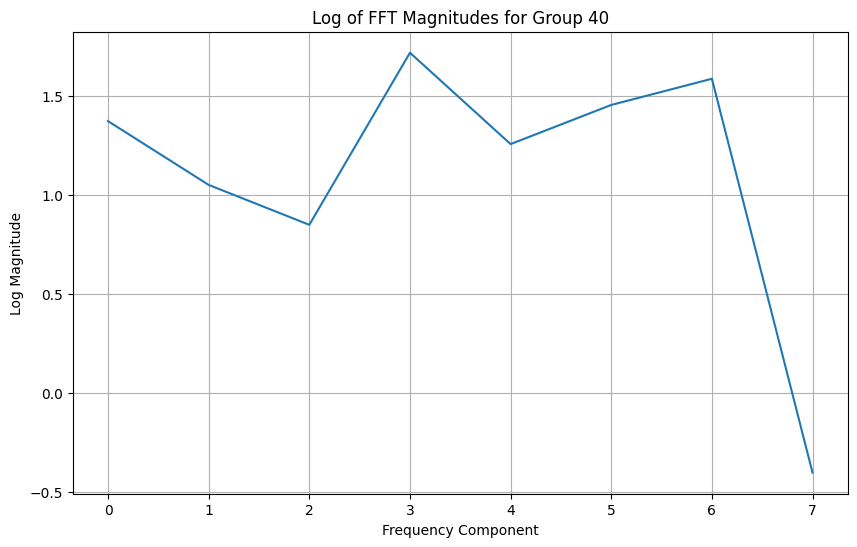

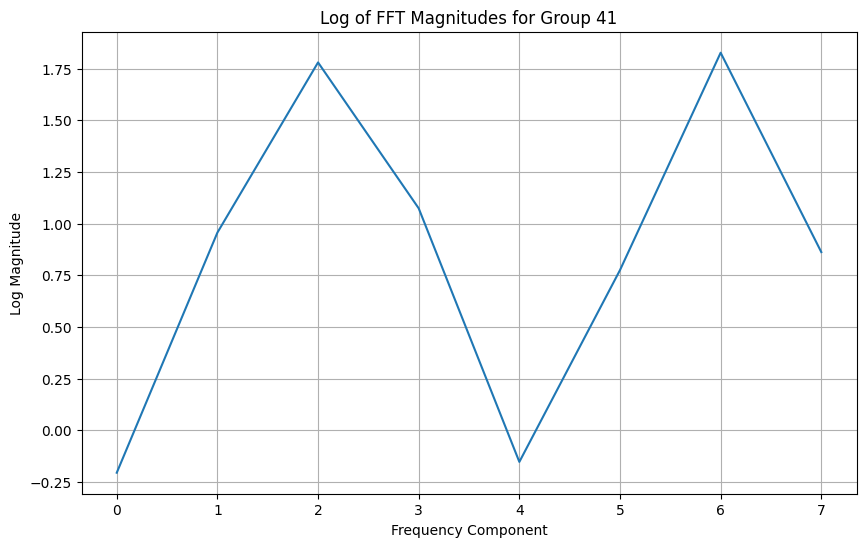

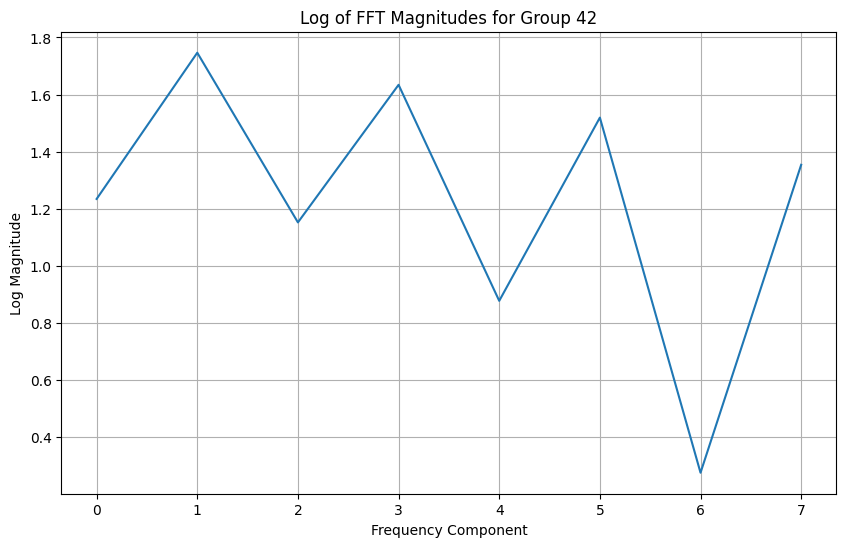

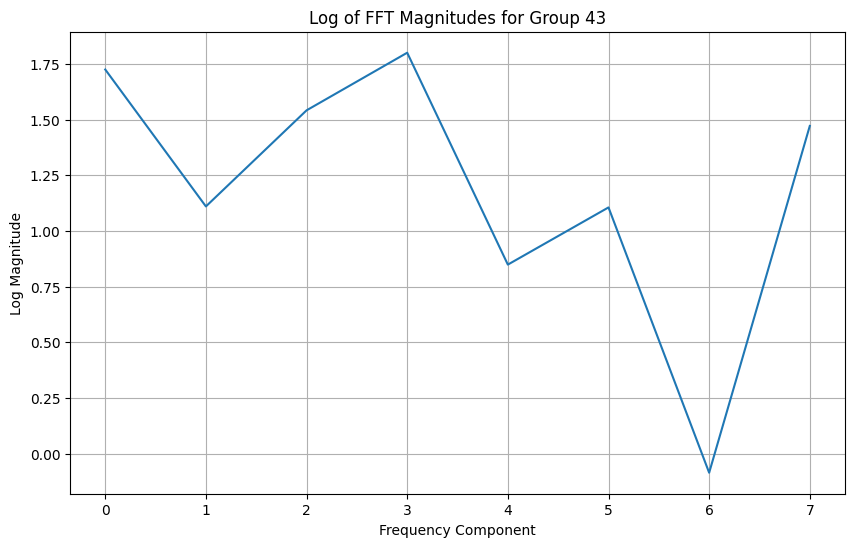

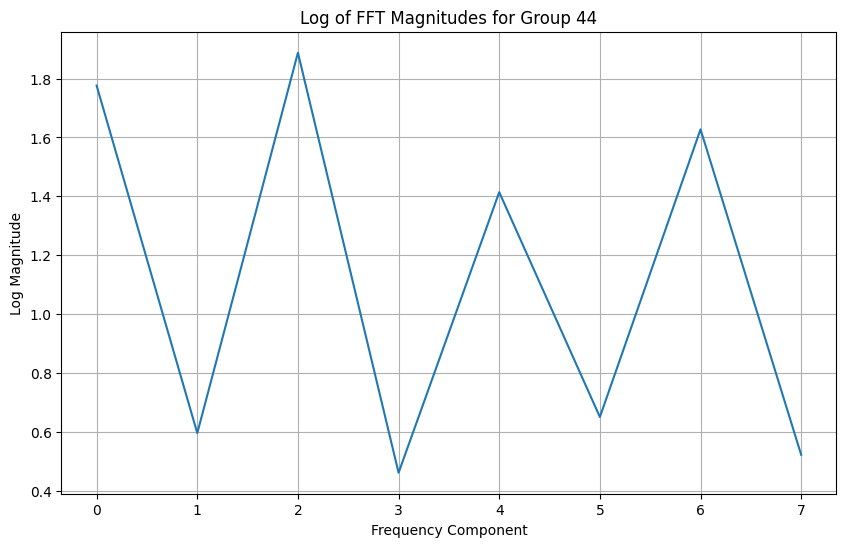

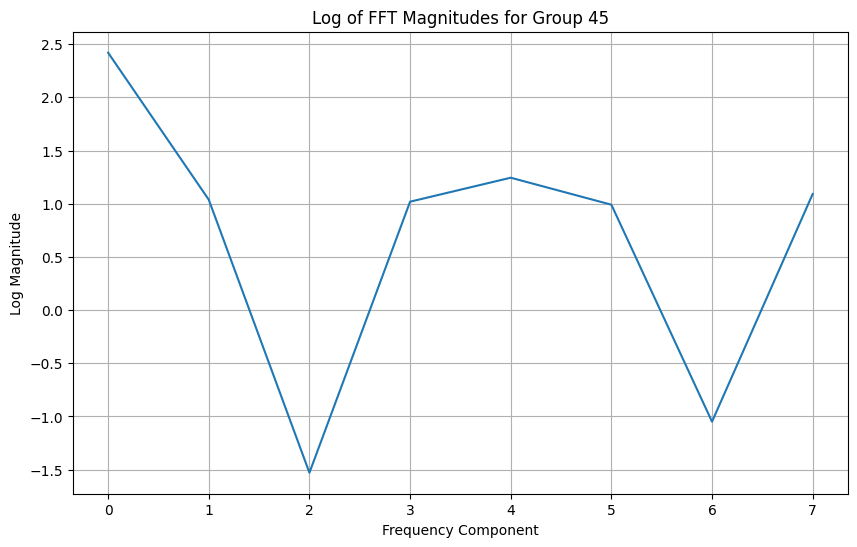

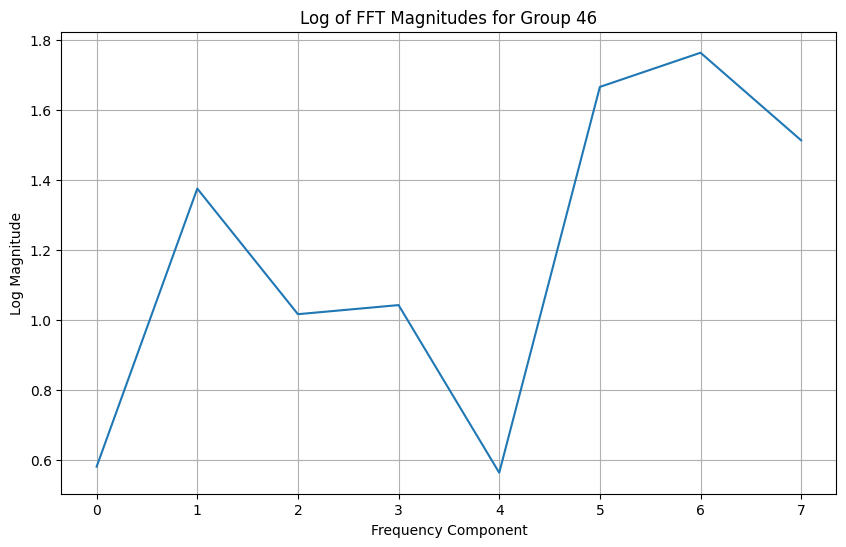

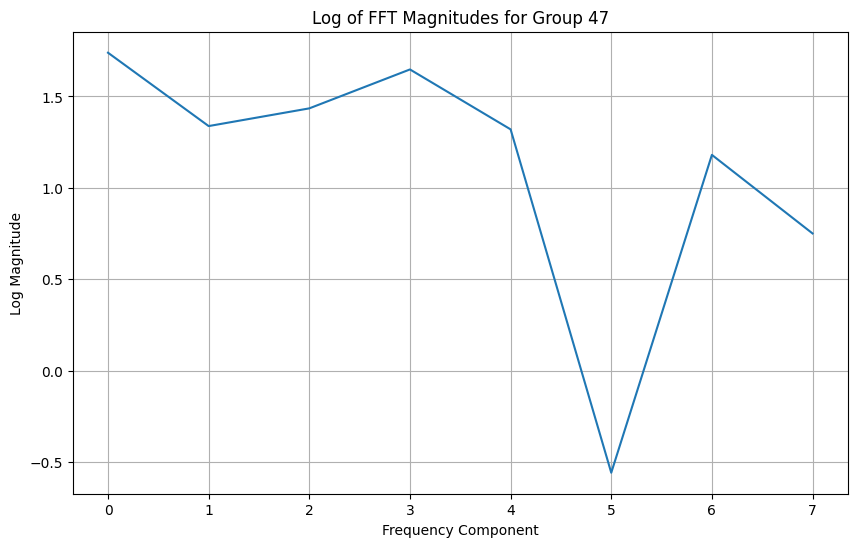

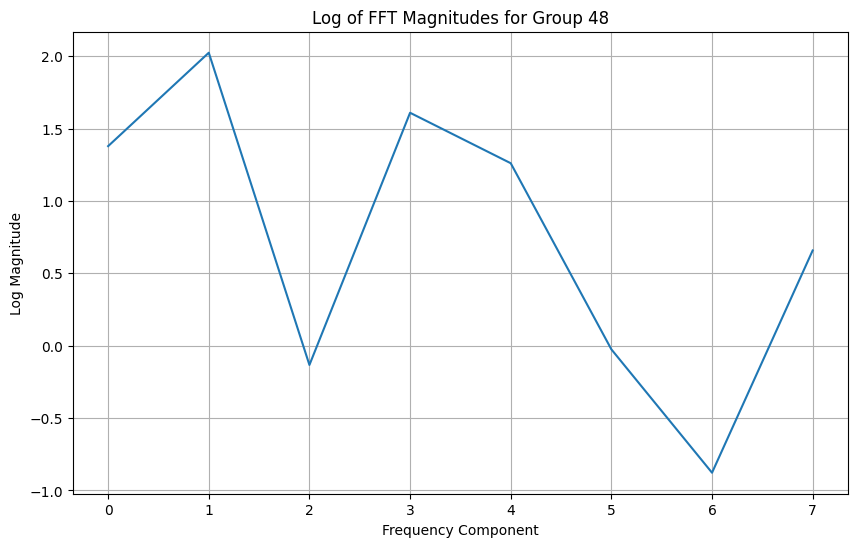

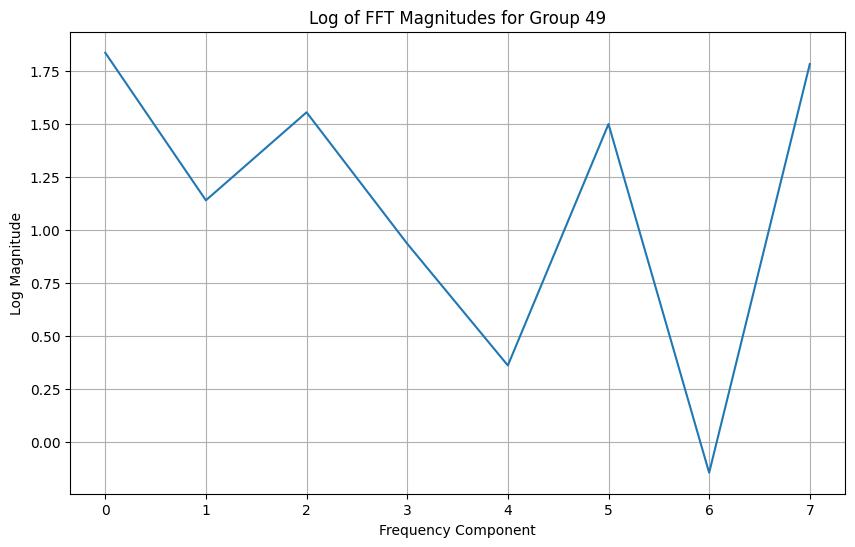

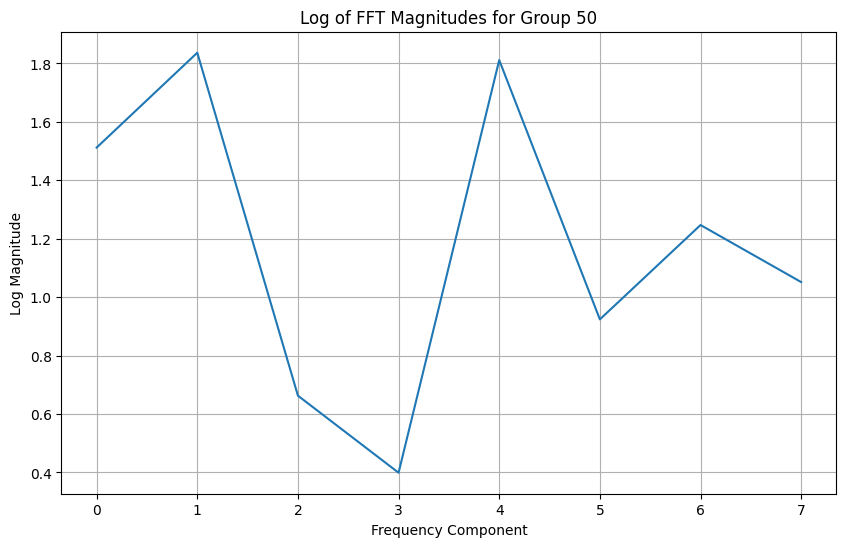

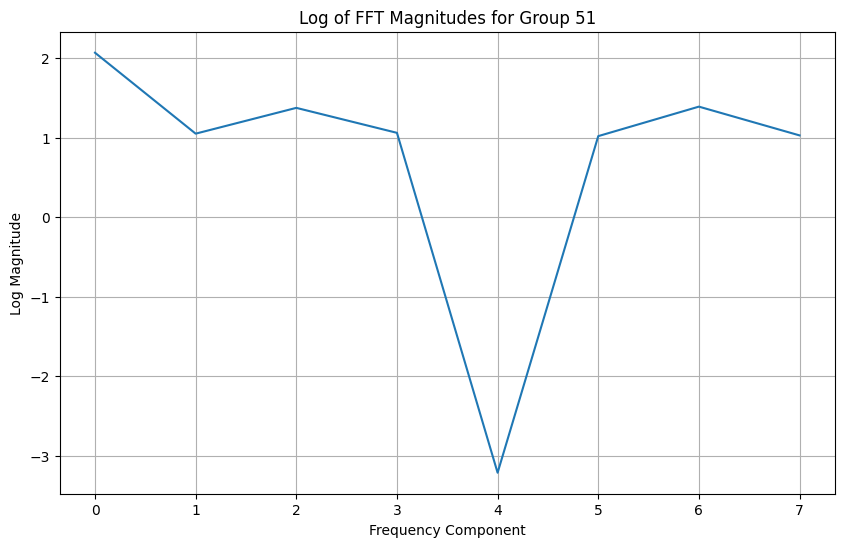

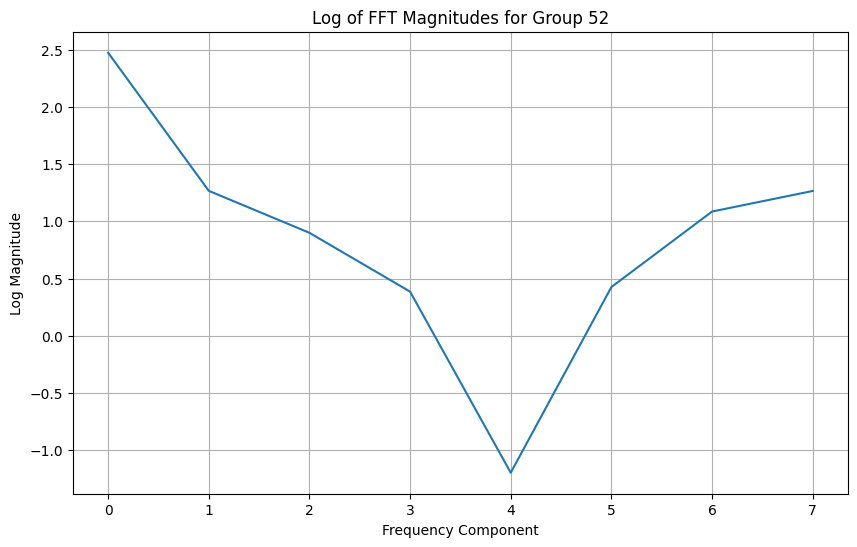

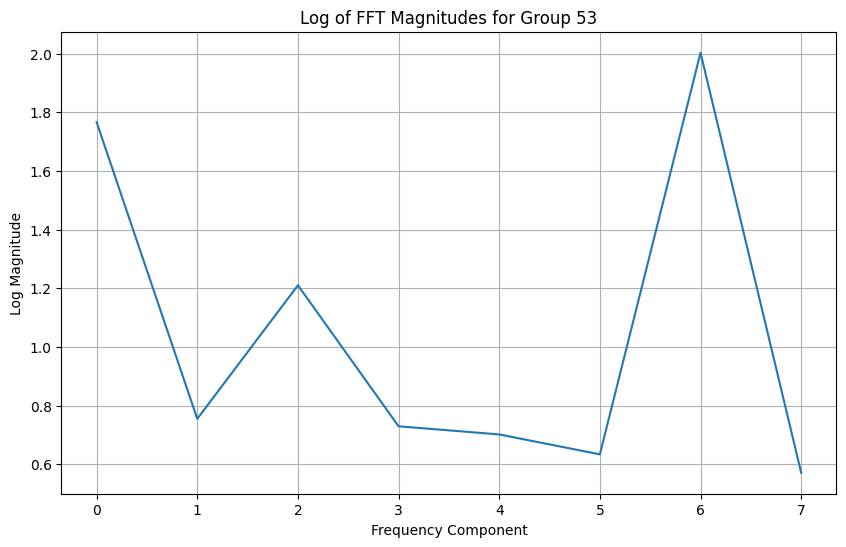

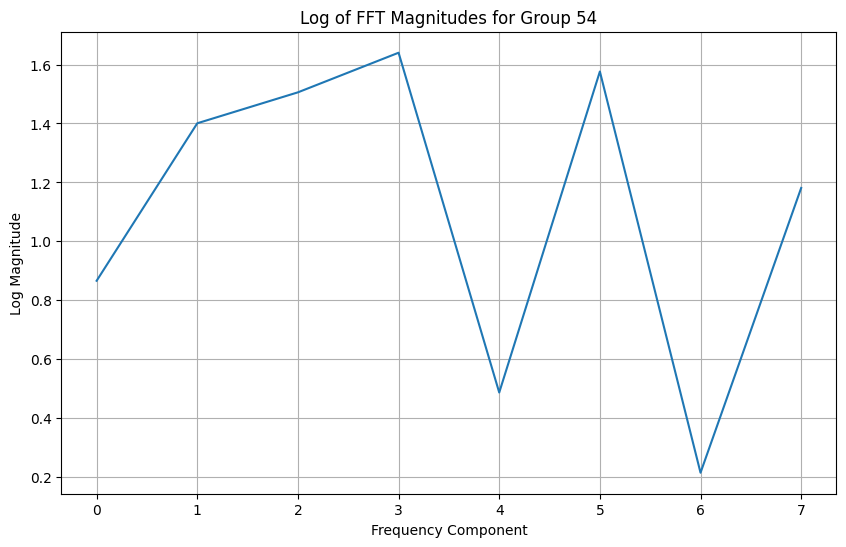

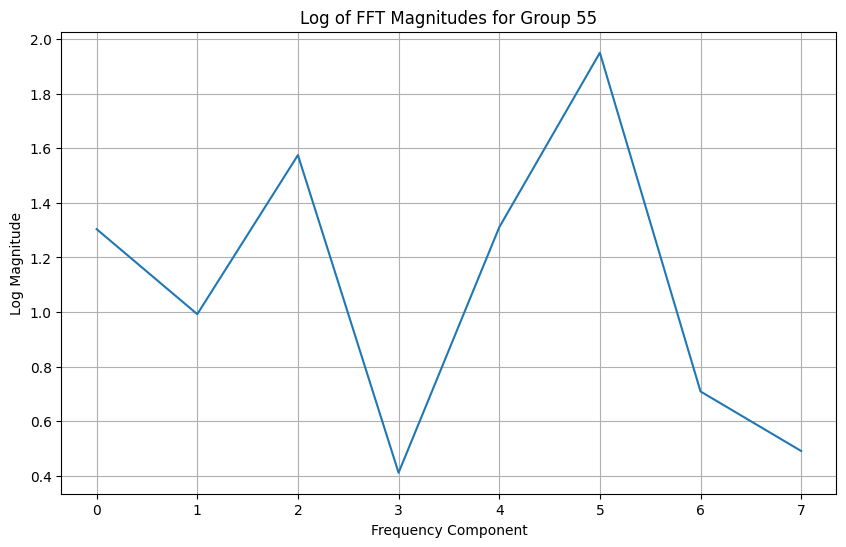

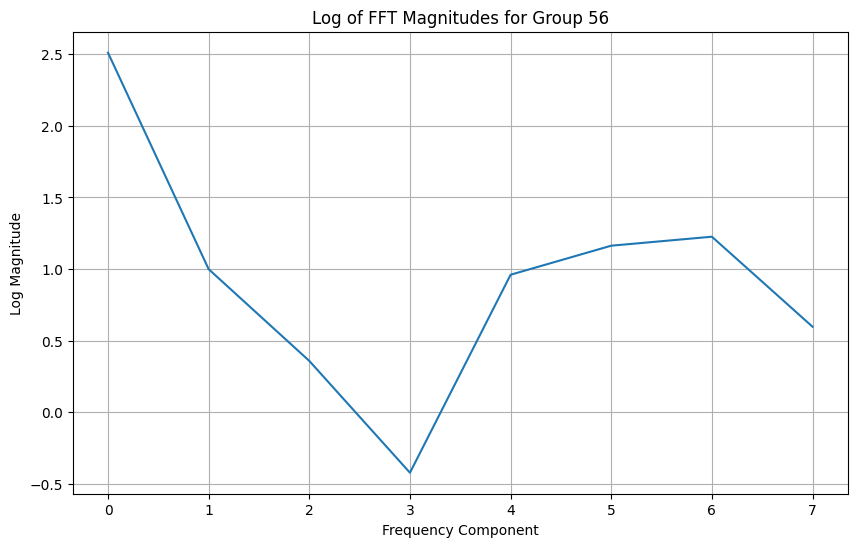

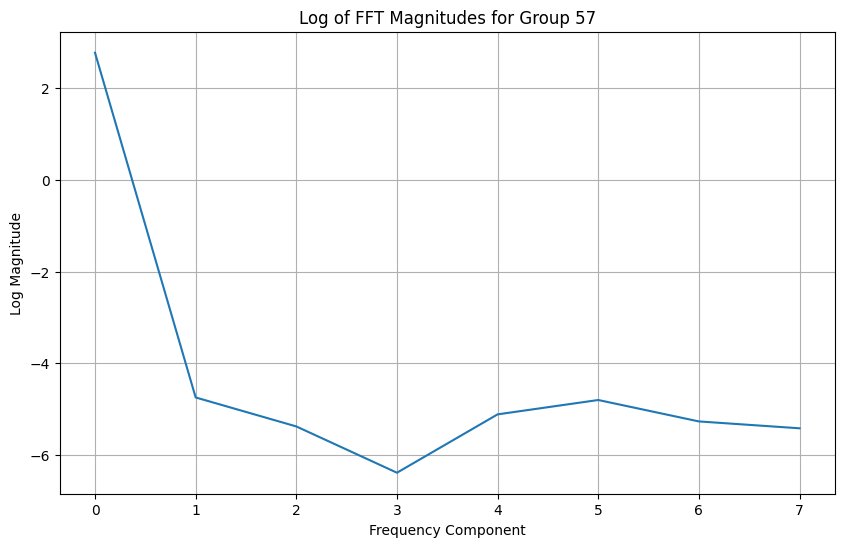

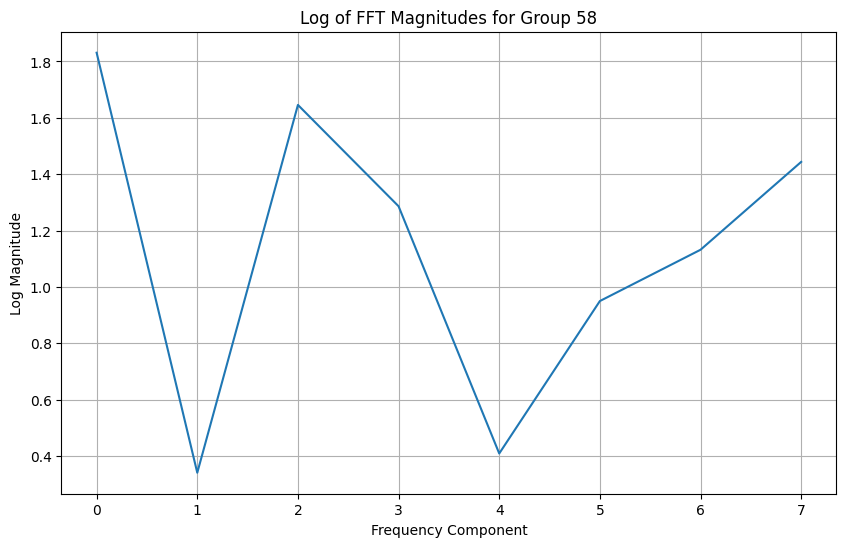

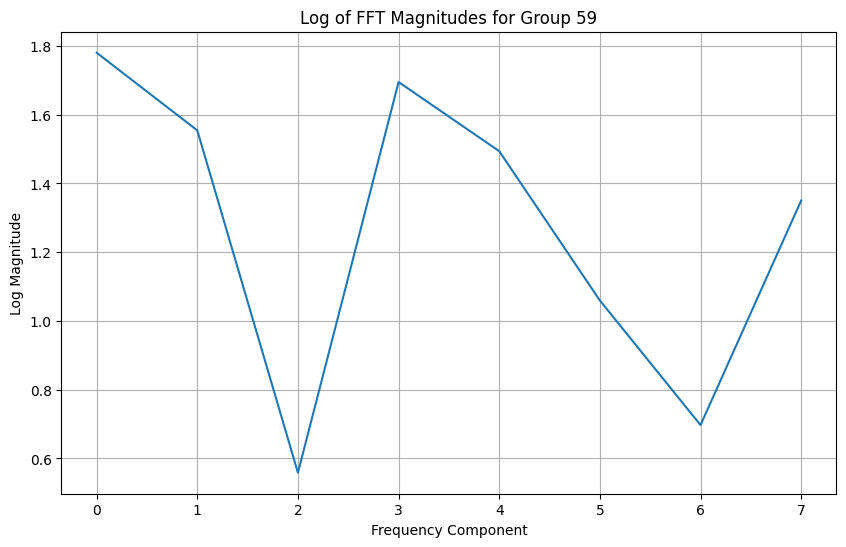

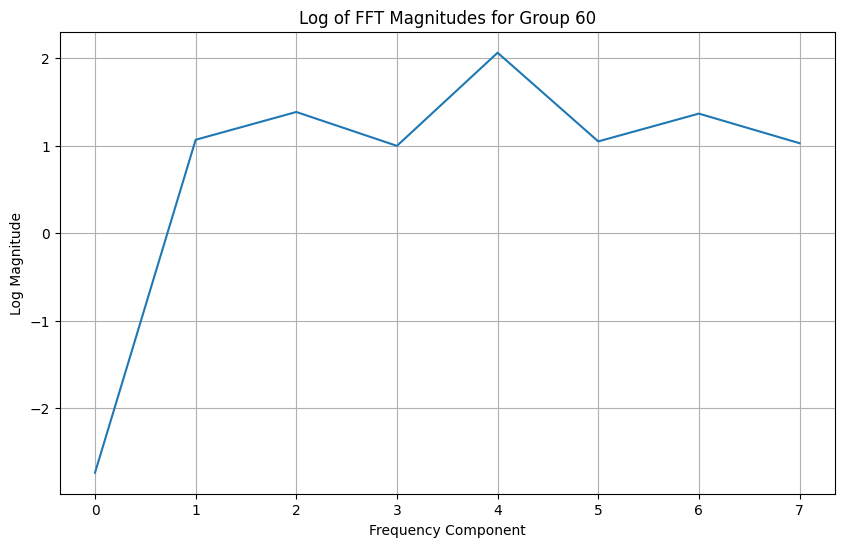

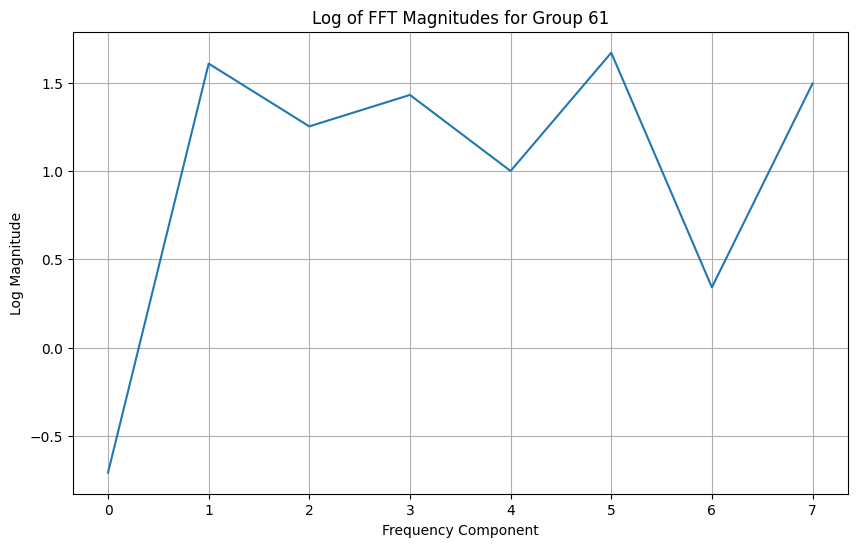

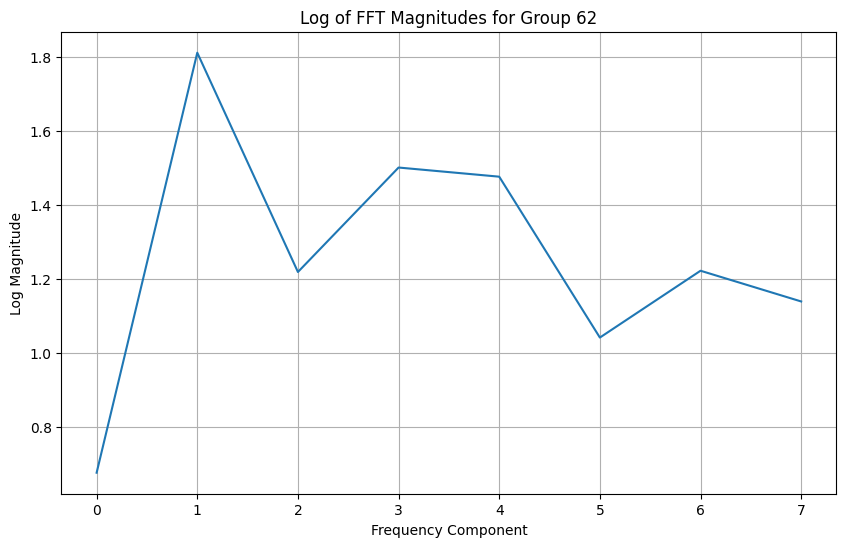

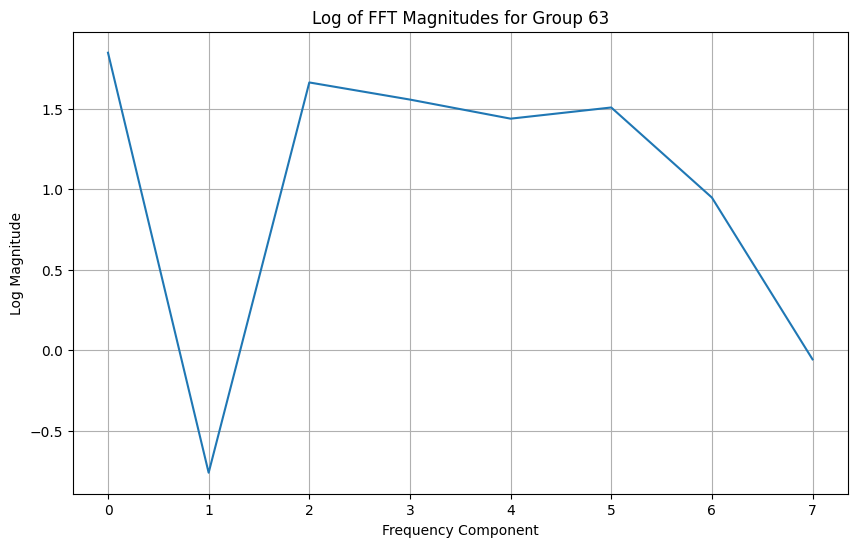

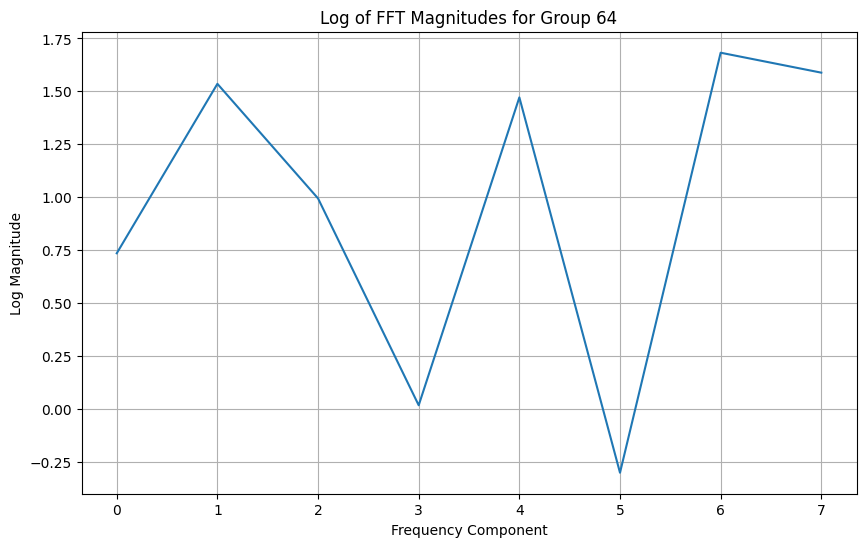

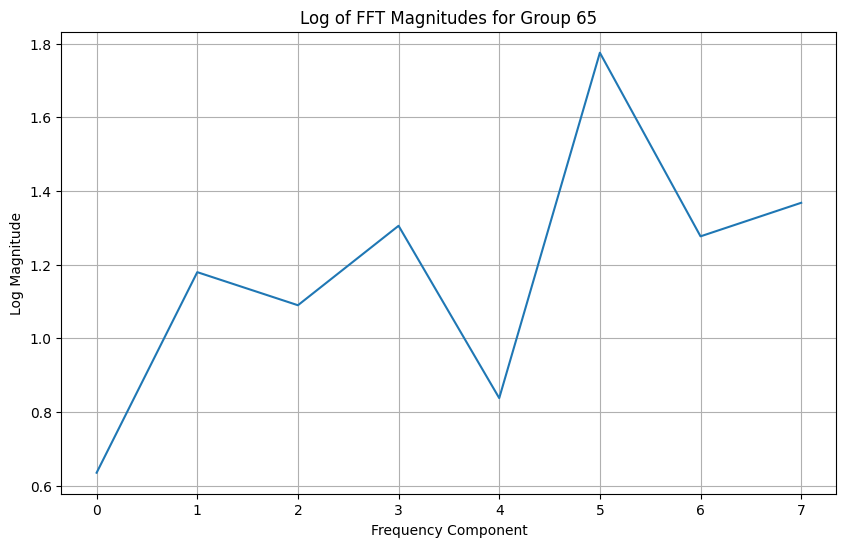

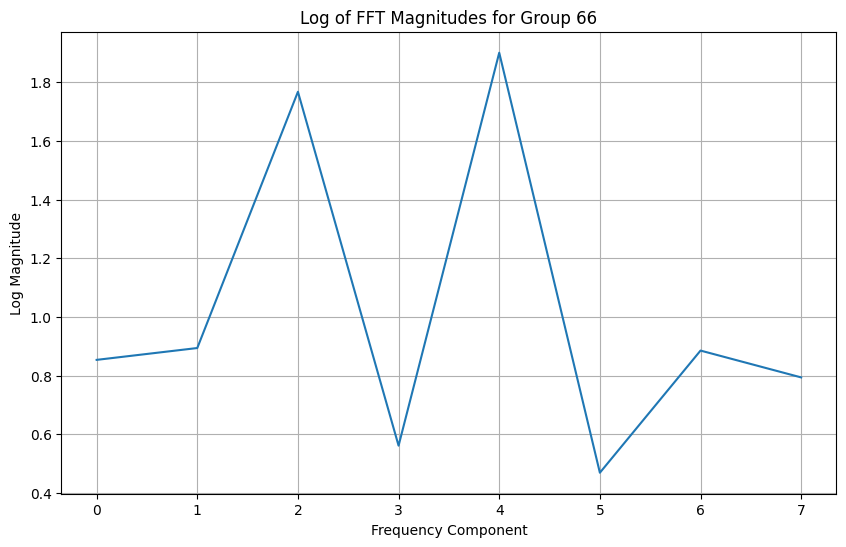

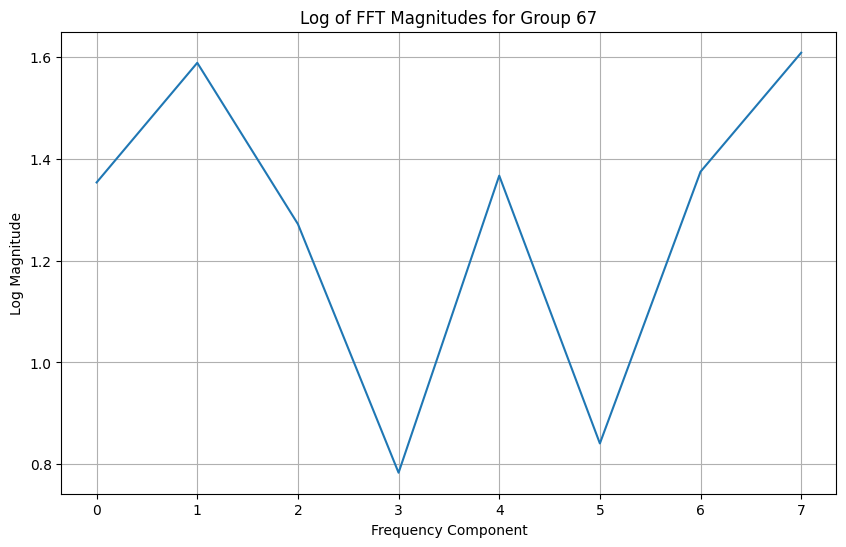

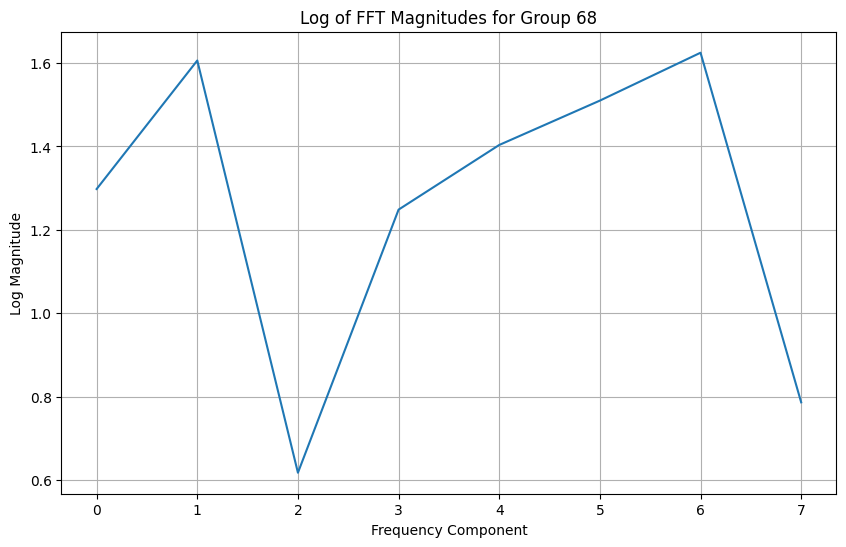

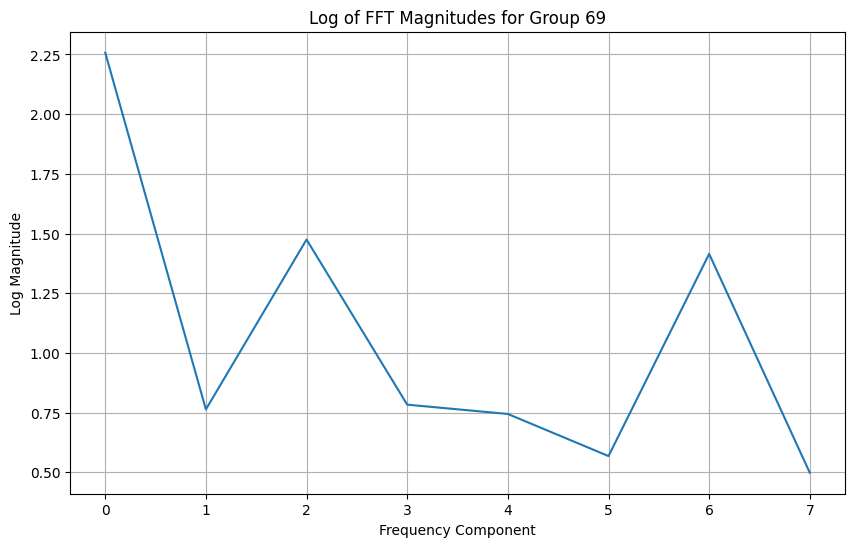

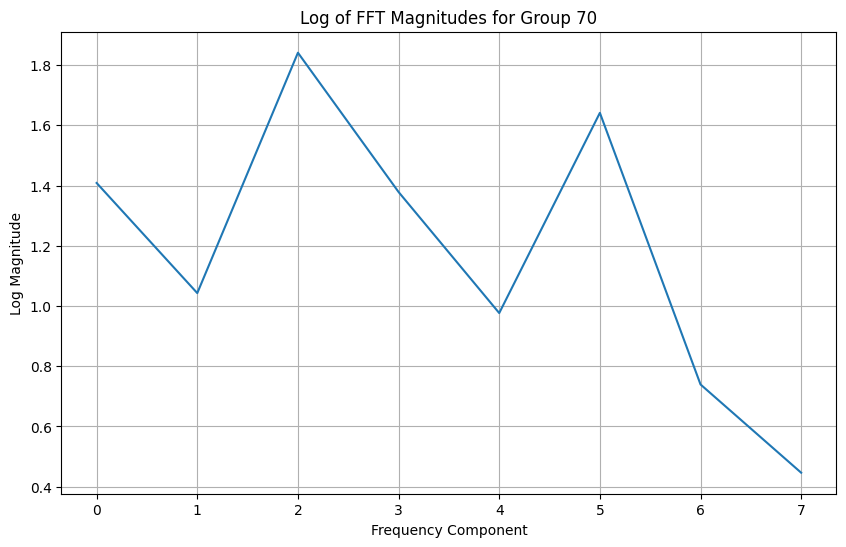

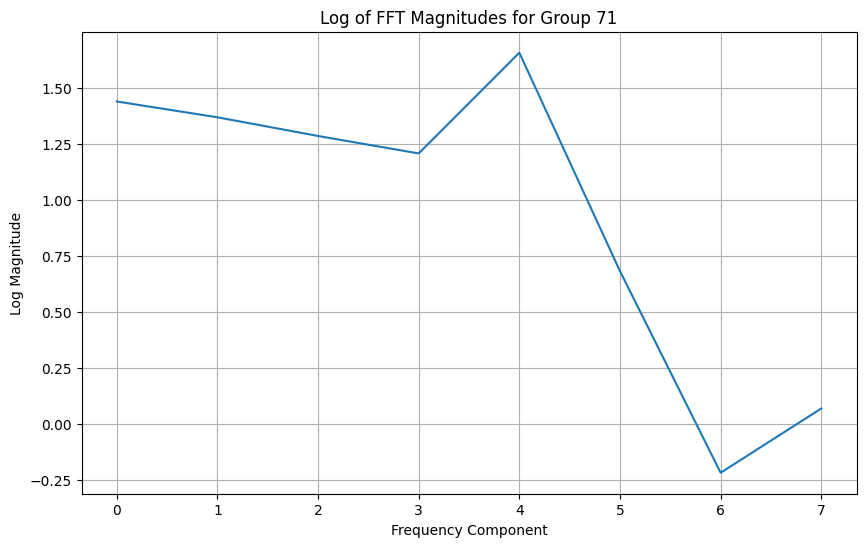

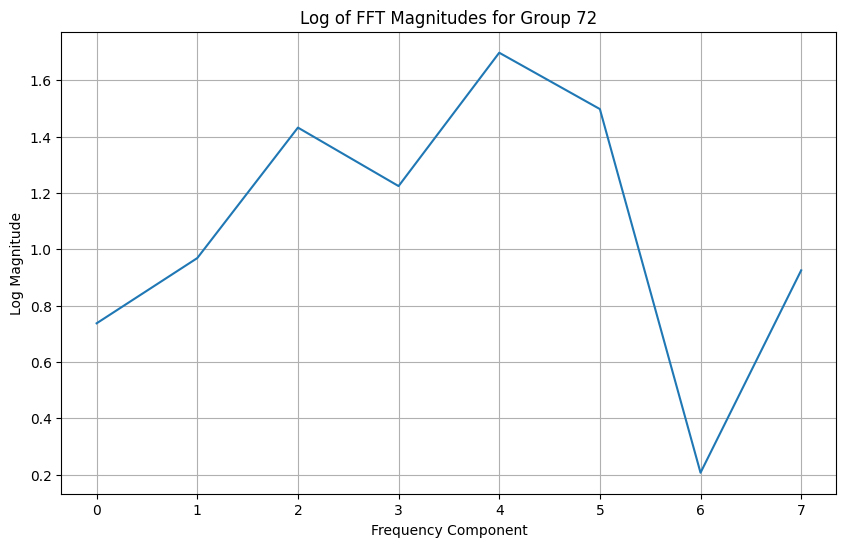

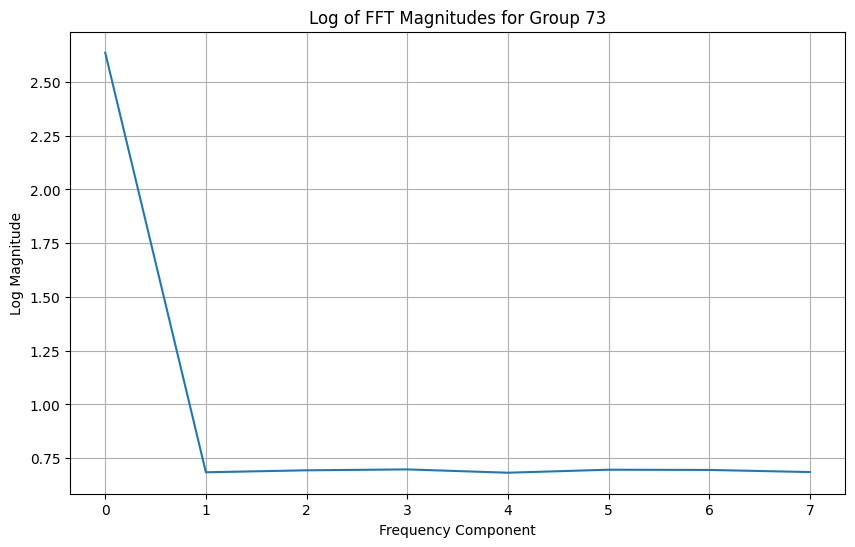

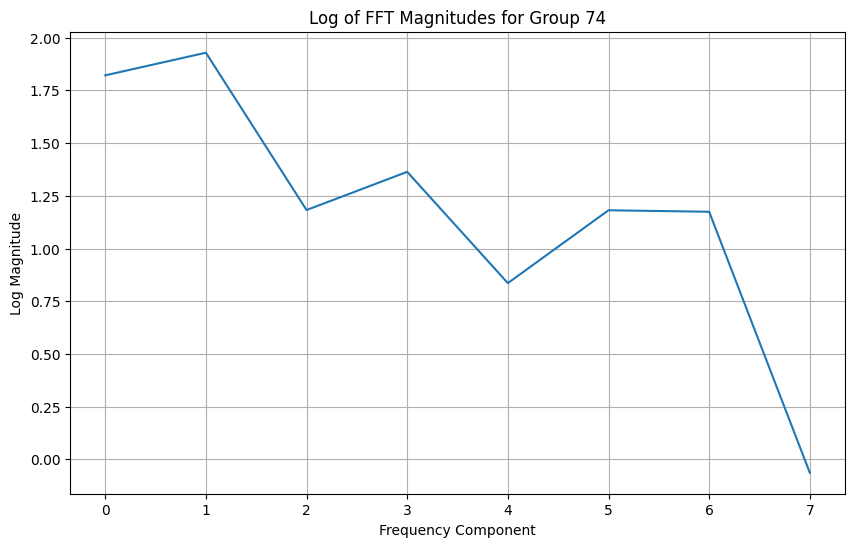

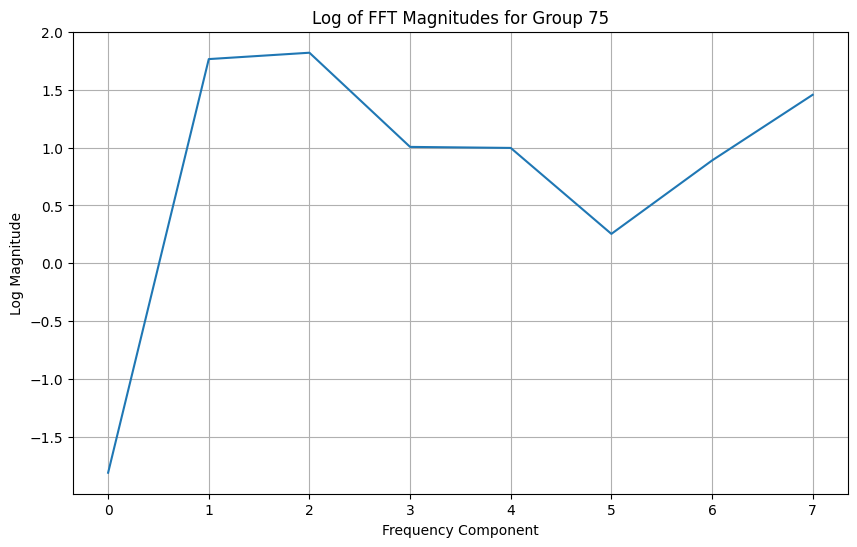

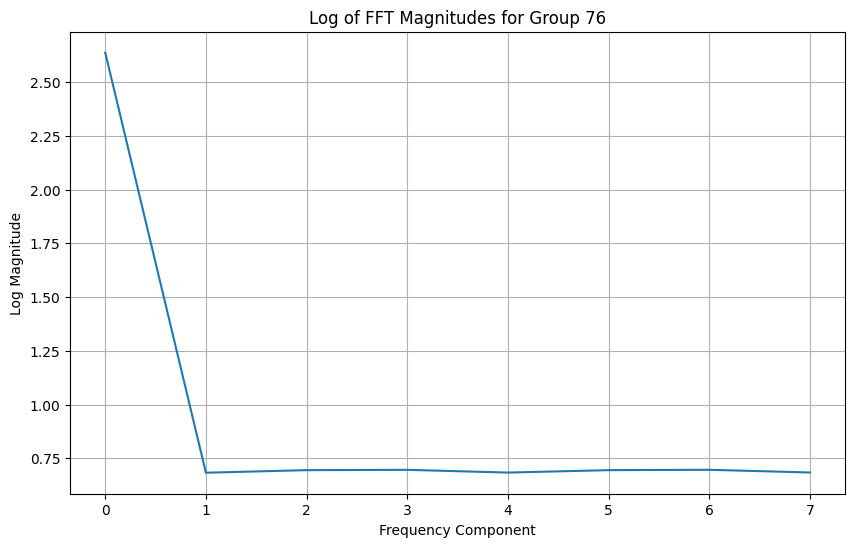

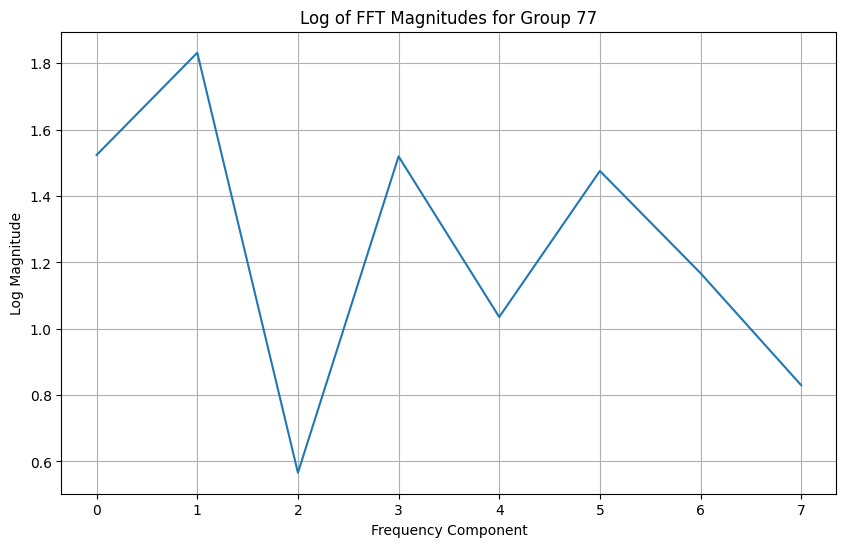

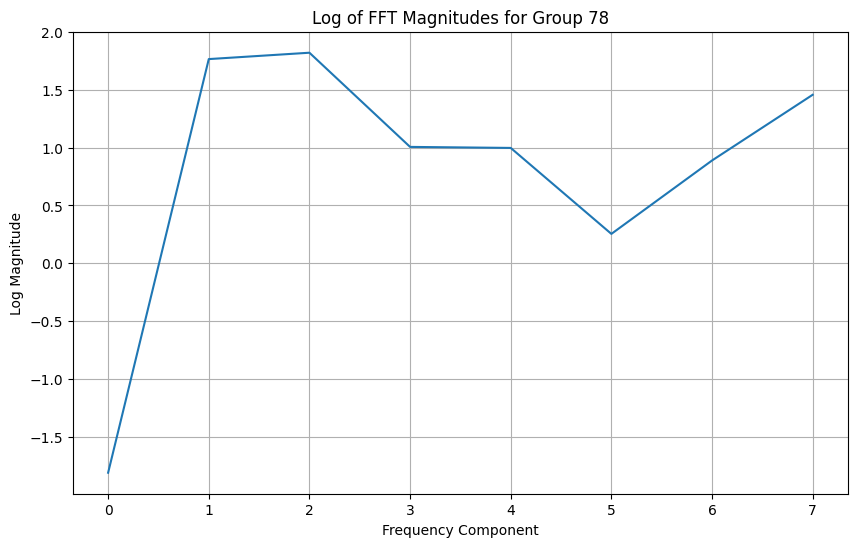

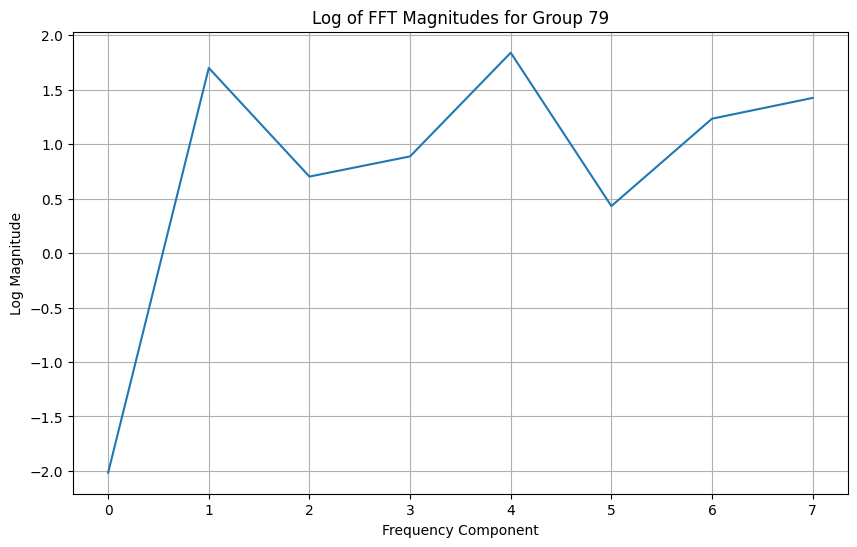

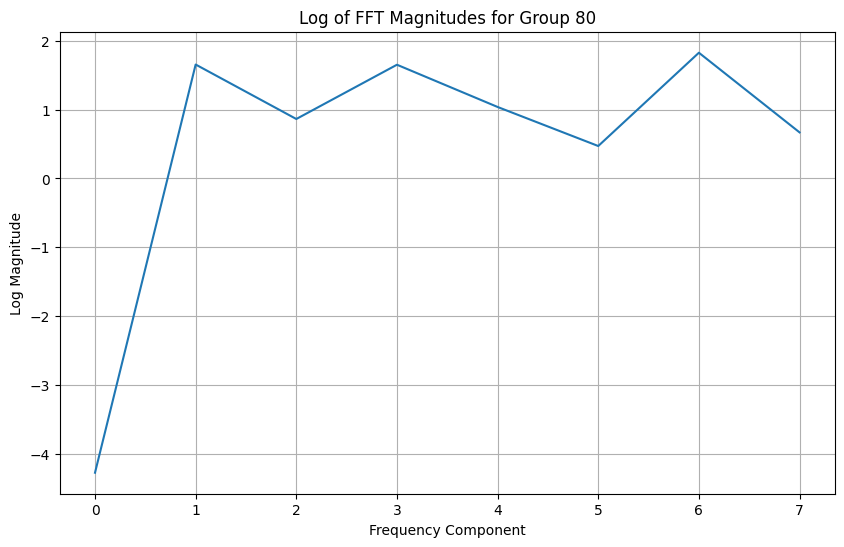

In [99]:
for i, df in enumerate(dfs):
    plot_fft(df, f"Group {i+1}")

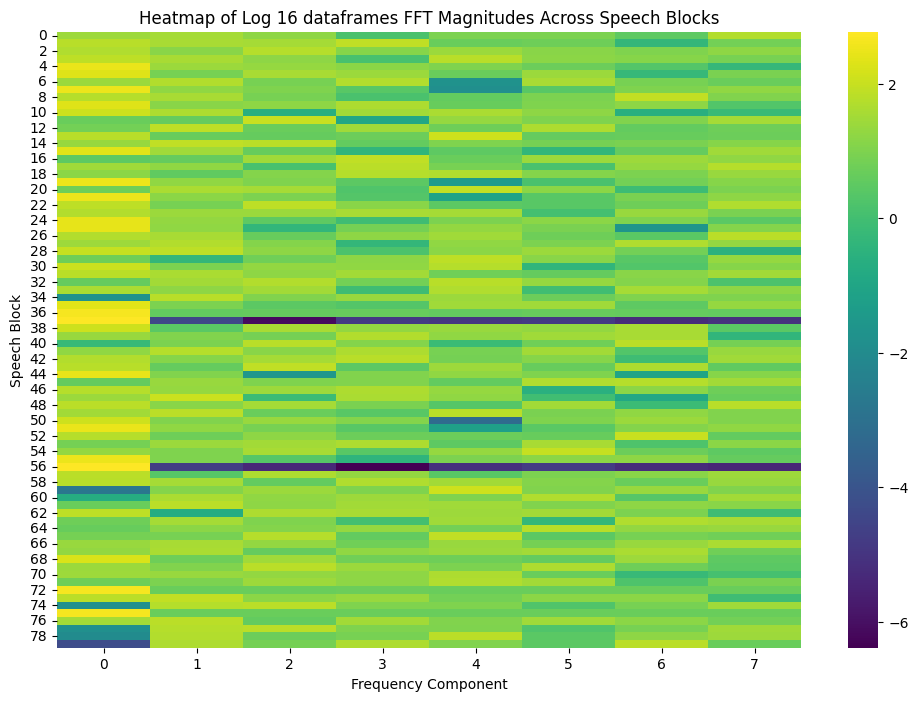

In [101]:
log_fft_magnitudes_list = [compute_log_fft_magnitudes(df) for df in dfs]
log_fft_magnitudes_matrix = np.vstack(log_fft_magnitudes_list)

plt.figure(figsize=(12, 8))
sns.heatmap(log_fft_magnitudes_matrix, cmap='viridis', cbar=True)
plt.title('Heatmap of Log 16 dataframes FFT Magnitudes Across Speech Blocks')
plt.xlabel('Frequency Component')
plt.ylabel('Speech Block')
plt.show()


In [ ]:
#Observation and inference
#By applying FFT to sentiment scores, the notebook is analyzing how the sentiment scores' intensity varies at different frequency components.
#The heatmap provides a visual summary of the FFT magnitudes across multiple speech blocks, making it easier to compare and contrast the frequency components between different sections of the speech. This could be used to identify consistent patterns or anomalies in sentiment across different parts of a speech or across different speeches.
#Uniform Patterns: If the heatmap shows similar intensity across many blocks and frequencies, it may indicate a consistent pattern in how sentiment evolves over different speeches or parts of a speech.
#Varied Patterns: Differences in intensity across the heatmap can indicate changes in the nature of sentiment fluctuations, possibly reflecting different emotional responses depending on the content or context of the speech.

#Darker colors (such as deep purple) indicate lower magnitudes. This suggests less variation in the sentiment scores within those particular speech blocks.
#In darker colours, there isn't a strong rhythmic pattern in the sentiment changes. 

#Brighter colors (yellows and greens) suggest higher magnitudes, indicating a stronger presence or greater variation of the sentiment scores at those frequencies. If there are consistent patterns across many blocks (e.g., certain frequencies are always dark or bright), it may indicate rhythmic or recurring sentiment variations across the speeches.

#Brighter could suggest an emotional diversity in the speeches, with the author possibly trying to evoke a range of responses or convey a dynamic message.

#Conversely, if the heatmap is relatively dark, it could suggest that the author maintains a consistent sentiment throughout the speeches. This might be indicative of a deliberate attempt to project a stable emotional state or a consistent motivational message.